## Importing libraries

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Reading CSV files

In [4]:

constraints = pd.read_csv("constraints.csv")
resources = pd.read_csv("resources.csv")
schedule_runs = pd.read_csv("schedule_runs.csv")
staffs = pd.read_csv("staff.csv")
tasks = pd.read_csv("tasks.csv")
assignments = pd.read_csv("assignments.csv")
audit_logs = pd.read_csv("audit_logs.csv")

print("All CSV files loaded successfully!")

All CSV files loaded successfully!


## Dimension of data

In [6]:
print("Tasks:", tasks.shape)
print("Resources:", resources.shape)
print("Staff:", staffs.shape)
print("Constraints:", constraints.shape)
print("Schedule runs:", schedule_runs.shape)
print("Assignments:", assignments.shape)
print("Audit logs:", audit_logs.shape)

Tasks: (30, 15)
Resources: (21, 11)
Staff: (15, 10)
Constraints: (3, 11)
Schedule runs: (2, 17)
Assignments: (60, 11)
Audit logs: (5, 8)


In [7]:
datasets = {
    "tasks": tasks,
    "resources": resources,
    "staffs": staffs,
    "constraints": constraints,
    "schedule_runs": schedule_runs,
    "assignments": assignments,
    "audit_logs": audit_logs
}

for name, df in datasets.items():
    print(f"\n{'=' * 60}")
    print(f"DATASET: {name}")
    print("=" * 60)
    print(df.dtypes)
    


DATASET: tasks
id                         int64
task_id                   object
title                     object
category                  object
description               object
duration_minutes           int64
priority                   int64
earliest_start            object
deadline                  object
required_resource_type    object
required_skill            object
scheduling_status         object
is_active                  int64
created_at                object
updated_at                object
dtype: object

DATASET: resources
id                      int64
resource_id            object
name                   object
resource_type          object
capacity                int64
availability_status    object
maintenance_status     object
availability_notes     object
is_active               int64
created_at             object
updated_at             object
dtype: object

DATASET: staffs
id                      int64
staff_id               object
name                   object
role

In [8]:
for name, df in datasets.items():
    print(f"\n{'=' * 60}")
    print(f"DATASET: {name}")
    print("=" * 60)
    display(df.head(3))



DATASET: tasks


,id,task_id,title,category,description,duration_minutes,priority,earliest_start,deadline,required_resource_type,required_skill,scheduling_status,is_active,created_at,updated_at
0,1,TSK-001,Basic Logistics Orientation,training,Introductory training for new logistics personnel,120,2,2026-07-14 06:00:00.000000,2026-07-14 14:00:00.000000,training_facility,instruction,unscheduled,1,2026-10-10 06:34:56.093927,2026-10-10 06:34:56.093927
1,2,TSK-002,Vehicle Safety Refresher,training,Annual vehicle safety refresher course,90,2,2026-07-14 06:00:00.000000,2026-07-14 16:00:00.000000,training_facility,instruction,unscheduled,1,2026-10-10 06:34:56.093927,2026-10-10 06:34:56.093927
2,3,TSK-003,Cargo Handling Certification,training,Certification training for cargo handlers,180,3,2026-07-14 08:00:00.000000,2026-07-14 18:00:00.000000,training_facility,instruction,unscheduled,1,2026-10-10 06:34:56.093927,2026-10-10 06:34:56.093927



DATASET: resources


,id,resource_id,name,resource_type,capacity,availability_status,maintenance_status,availability_notes,is_active,created_at,updated_at
0,1,RES-001,Transport Truck Alpha,transport_vehicle,10,available,operational,NaN,1,2026-10-10 06:34:56.091847,2026-10-10 06:34:56.091847
1,2,RES-002,Transport Truck Bravo,transport_vehicle,10,available,operational,NaN,1,2026-10-10 06:34:56.091847,2026-10-10 06:34:56.091847
2,3,RES-003,Transport Truck Charlie,transport_vehicle,8,available,operational,NaN,1,2026-10-10 06:34:56.091847,2026-10-10 06:34:56.091847



DATASET: staffs


...

,id,schedule_id,version,status,solver_status,objective_score,runtime_seconds,total_tasks,scheduled_tasks,unscheduled_tasks,scenario_description,parent_schedule_id,reviewer_id,review_notes,reviewed_at,created_at,updated_at
0,1,SCH-E85ECE1C,1,PENDING_REVIEW,OPTIMAL,107.0,0.130387,30,29,1,NaN,NaN,NaN,NaN,NaN,2026-10-10 06:35:12.196892,2026-10-10 06:35:12.196892
1,2,SCH-BC2EBE38,1,PENDING_REVIEW,OPTIMAL,107.0,0.023001,30,29,1,NaN,NaN,NaN,NaN,NaN,2026-10-10 07:02:17.849980,2026-10-10 07:02:17.849980



DATASET: assignments


,id,schedule_run_id,task_id,resource_id,staff_id,start_time,end_time,is_scheduled,unscheduled_reason,explanation,created_at
0,1,1,TSK-001,RES-005,STF-006,2026-07-14 06:00:00.000000,2026-07-14 08:00:00.000000,1,NaN,Scheduled from 2026-07-14 06:00 to 2026-07-14 ...,2026-10-10 06:35:12.199804
1,2,1,TSK-002,RES-006,STF-005,2026-07-14 06:00:00.000000,2026-07-14 07:30:00.000000,1,NaN,Scheduled from 2026-07-14 06:00 to 2026-07-14 ...,2026-10-10 06:35:12.199804
2,3,1,TSK-003,RES-005,STF-005,2026-07-14 08:00:00.000000,2026-07-14 11:00:00.000000,1,NaN,Scheduled from 2026-07-14 08:00 to 2026-07-14 ...,2026-10-10 06:35:12.199804



DATASET: audit_logs


,id,event_type,entity_type,entity_id,actor,description,metadata_json,created_at
0,1,SEED_DATA_LOADED,system,system,system,"Demo seed data loaded: {'resources': 20, 'staf...",NaN,2026-10-10 06:34:56.087683
1,2,SCHEDULE_GENERATED,schedule,SCH-E85ECE1C,system,Schedule SCH-E85ECE1C generated. Status: OPTIM...,NaN,2026-10-10 06:35:12.198805
2,3,CSV_IMPORT,resources,bulk,user,"CSV import: 1 resources imported, 0 skipped",NaN,2026-10-10 07:02:00.840550


## Missing value of every dataset

In [10]:
# Step 1: Missing-value profile for every dataset

for name, df in datasets.items():
    print(f"\n{'=' * 60}")
    print(f"DATASET: {name}")
    print(f"Total rows: {len(df)}")
    print("=" * 60)

    missing_count = df.isna().sum()
    missing_percent = (missing_count / len(df)) * 100

    profile = pd.DataFrame({
        "missing_count": missing_count,
        "missing_percent": missing_percent.round(2)
    })

    profile = profile[profile["missing_count"] > 0]

    if profile.empty:
        print("No standard missing values detected.")
    else:
        display(profile)


DATASET: tasks
Total rows: 30
No standard missing values detected.

DATASET: resources
Total rows: 21


,missing_count,missing_percent
availability_notes,20,95.24



DATASET: staffs
Total rows: 15


,missing_count,missing_percent
availability_notes,14,93.33



DATASET: constraints
Total rows: 3
No standard missing values detected.

DATASET: schedule_runs
Total rows: 2


,missing_count,missing_percent
scenario_description,2,100.0
parent_schedule_id,2,100.0
reviewer_id,2,100.0
review_notes,2,100.0
reviewed_at,2,100.0



DATASET: assignments
Total rows: 60


,missing_count,missing_percent
resource_id,2,3.33
staff_id,2,3.33
start_time,2,3.33
end_time,2,3.33
unscheduled_reason,58,96.67



DATASET: audit_logs
Total rows: 5


,missing_count,missing_percent
metadata_json,5,100.0


In [11]:
# Inspect only rows with at least one missing value
# in the assignment-related columns.

columns_to_check = [
    "task_id",
    "resource_id",
    "staff_id",
    "start_time",
    "end_time",
    "is_scheduled",
    "unscheduled_reason",
    "schedule_run_id"
]

missing_assignment_rows = assignments.loc[
    assignments[columns_to_check].isna().any(axis=1),
    columns_to_check
]

display(missing_assignment_rows)

,task_id,resource_id,staff_id,start_time,end_time,is_scheduled,unscheduled_reason,schedule_run_id
0,TSK-001,RES-005,STF-006,2026-07-14 06:00:00.000000,2026-07-14 08:00:00.000000,1,NaN,1
1,TSK-002,RES-006,STF-005,2026-07-14 06:00:00.000000,2026-07-14 07:30:00.000000,1,NaN,1
2,TSK-003,RES-005,STF-005,2026-07-14 08:00:00.000000,2026-07-14 11:00:00.000000,1,NaN,1
3,TSK-004,RES-006,STF-005,2026-07-14 11:00:00.000000,2026-07-14 12:00:00.000000,1,NaN,1
4,TSK-005,RES-007,STF-006,2026-07-14 12:00:00.000000,2026-07-14 13:30:00.000000,1,NaN,1
5,TSK-006,RES-001,STF-001,2026-07-14 08:45:00.000000,2026-07-14 11:15:00.000000,1,NaN,1
6,TSK-007,RES-001,STF-001,2026-07-14 12:45:00.000000,2026-07-14 13:45:00.000000,1,NaN,1
7,TSK-008,RES-001,STF-001,2026-07-14 13:45:00.000000,2026-07-14 15:15:00.000000,1,NaN,1
8,TSK-009,RES-001,STF-001,2026-07-14 06:00:00.000000,2026-07-14 08:00:00.000000,1,NaN,1
9,TSK-010,RES-001,STF-001,2026-07-14 08:00:00.000000,2026-07-14 08:45:00.000000,1,NaN,1


In [12]:
# Summarize scheduling outcomes
print("Scheduling status counts:")
display(assignments["is_scheduled"].value_counts(dropna=False).sort_index())

# Check missing values by scheduling status
missing_by_status = assignments.groupby(
    "is_scheduled",
    dropna=False
)[
    [
        "resource_id",
        "staff_id",
        "start_time",
        "end_time",
        "unscheduled_reason"
    ]
].apply(lambda group: group.isna().sum())

print("\nMissing values by scheduling status:")
display(missing_by_status)

Scheduling status counts:


is_scheduled
0     2
1    58
Name: count, dtype: int64


Missing values by scheduling status:


,resource_id,staff_id,start_time,end_time,unscheduled_reason
is_scheduled,,,,,
0,2,2,2,2,0
1,0,0,0,0,58


## Checking duplicate Values

In [14]:

exact_duplicates = assignments.duplicated().sum()

print("Exact duplicate rows:", exact_duplicates)

# Check whether tasks appear in multiple schedule runs
task_run_counts = (
    assignments.groupby("task_id")["schedule_run_id"]
    .nunique()
    .sort_values(ascending=False)
)

print("\nNumber of distinct schedule runs per task:")
display(task_run_counts.value_counts().sort_index())

print("\nTasks appearing in more than one schedule run:")
display(task_run_counts[task_run_counts > 1])

Exact duplicate rows: 0

Number of distinct schedule runs per task:


schedule_run_id
2    30
Name: count, dtype: int64


Tasks appearing in more than one schedule run:


task_id
TSK-001    2
TSK-002    2
TSK-029    2
TSK-028    2
TSK-027    2
TSK-026    2
TSK-025    2
TSK-024    2
TSK-023    2
TSK-022    2
TSK-021    2
TSK-020    2
TSK-019    2
TSK-018    2
TSK-017    2
TSK-016    2
TSK-015    2
TSK-014    2
TSK-013    2
TSK-012    2
TSK-011    2
TSK-010    2
TSK-009    2
TSK-008    2
TSK-007    2
TSK-006    2
TSK-005    2
TSK-004    2
TSK-003    2
TSK-030    2
Name: schedule_run_id, dtype: int64

In [15]:
# Compare the two schedule runs
comparison_columns = [
    "task_id",
    "resource_id",
    "staff_id",
    "start_time",
    "end_time",
    "is_scheduled",
    "unscheduled_reason"
]

run_1 = (
    assignments[assignments["schedule_run_id"] == 1]
    [comparison_columns]
    .set_index("task_id")
    .sort_index()
)

run_2 = (
    assignments[assignments["schedule_run_id"] == 2]
    [comparison_columns]
    .set_index("task_id")
    .sort_index()
)

# Compare assignment details for matching tasks
comparison = run_1.compare(
    run_2,
    keep_equal=False
)

print("Number of tasks with differences between runs:",
      len(comparison.index.unique()))

display(comparison)

Number of tasks with differences between runs: 3


resource_id         
               self    other
task_id                     
TSK-001     RES-005  RES-006
TSK-002     RES-006  RES-005
TSK-004     RES-006  RES-005

In [16]:
# Inspect the resources used by the changed assignments
changed_resource_ids = ["RES-005", "RES-006"]

resource_details = resources.loc[
    resources["resource_id"].isin(changed_resource_ids)
]

display(resource_details)

,id,resource_id,name,resource_type,capacity,availability_status,maintenance_status,availability_notes,is_active,created_at,updated_at
4,5,RES-005,Training Hall A,training_facility,30,available,operational,NaN,1,2026-10-10 06:34:56.091847,2026-10-10 06:34:56.091847
5,6,RES-006,Training Hall B,training_facility,25,available,operational,NaN,1,2026-10-10 06:34:56.091847,2026-10-10 06:34:56.091847


In [17]:
# Inspect tasks whose resource assignments changed
changed_task_ids = ["TSK-001", "TSK-002", "TSK-004"]

task_details = tasks.loc[
    tasks["task_id"].isin(changed_task_ids),
    [
        "task_id",
        "title",
        "category",
        "duration_minutes",
        "priority",
        "required_resource_type",
        "required_skill",
        "earliest_start",
        "deadline",
        "scheduling_status"
    ]
]

display(task_details)

,task_id,title,category,duration_minutes,priority,required_resource_type,required_skill,earliest_start,deadline,scheduling_status
0,TSK-001,Basic Logistics Orientation,training,120,2,training_facility,instruction,2026-07-14 06:00:00.000000,2026-07-14 14:00:00.000000,unscheduled
1,TSK-002,Vehicle Safety Refresher,training,90,2,training_facility,instruction,2026-07-14 06:00:00.000000,2026-07-14 16:00:00.000000,unscheduled
3,TSK-004,Emergency Procedures Drill,training,60,1,training_facility,instruction,2026-07-14 06:00:00.000000,2026-07-14 12:00:00.000000,unscheduled


In [18]:
# Compare task status with assignment status
status_check = assignments.merge(
    tasks[["task_id", "scheduling_status"]],
    on="task_id",
    how="left"
)

display(
    status_check[
        ["task_id", "schedule_run_id", "is_scheduled", "scheduling_status"]
    ].sort_values(["task_id", "schedule_run_id"])
)

,task_id,schedule_run_id,is_scheduled,scheduling_status
0,TSK-001,1,1,unscheduled
30,TSK-001,2,1,unscheduled
1,TSK-002,1,1,unscheduled
31,TSK-002,2,1,unscheduled
2,TSK-003,1,1,unscheduled
32,TSK-003,2,1,unscheduled
3,TSK-004,1,1,unscheduled
33,TSK-004,2,1,unscheduled
4,TSK-005,1,1,unscheduled
34,TSK-005,2,1,unscheduled


In [19]:
# Check the distribution of scheduling outcomes
target_counts = assignments["is_scheduled"].value_counts().sort_index()

print("Scheduling outcome counts:")
display(target_counts)

print("\nScheduling outcome percentages:")
display(
    (assignments["is_scheduled"].value_counts(normalize=True) * 100)
    .sort_index()
    .round(2)
)

Scheduling outcome counts:


is_scheduled
0     2
1    58
Name: count, dtype: int64


Scheduling outcome percentages:


is_scheduled
0     3.33
1    96.67
Name: proportion, dtype: float64

## getting count of schedule & unschedule assignments

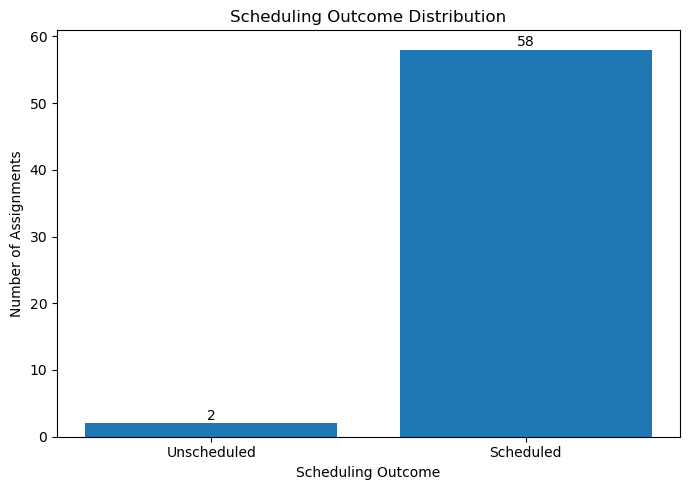

In [21]:
outcome_counts = assignments["is_scheduled"].value_counts().sort_index()

# Create readable labels of visualization 
outcome_labels = ["Unscheduled", "Scheduled"]

plt.figure(figsize=(7, 5))
plt.bar(outcome_labels, outcome_counts.values)

plt.title("Scheduling Outcome Distribution")
plt.xlabel("Scheduling Outcome")
plt.ylabel("Number of Assignments")

for i, count in enumerate(outcome_counts.values):
    plt.text(i, count + 0.5, str(count), ha="center")

plt.tight_layout()
plt.show()

## Analyzing columns required to create a Model

In [23]:
print("Assignment columns:")
print(assignments.columns.tolist())

print("\nTask columns:")
print(tasks.columns.tolist())

print("\nResource columns:")
print(resources.columns.tolist())

print("\nStaff columns:")
print(staffs.columns.tolist())

Assignment columns:
['id', 'schedule_run_id', 'task_id', 'resource_id', 'staff_id', 'start_time', 'end_time', 'is_scheduled', 'unscheduled_reason', 'explanation', 'created_at']

Task columns:
['id', 'task_id', 'title', 'category', 'description', 'duration_minutes', 'priority', 'earliest_start', 'deadline', 'required_resource_type', 'required_skill', 'scheduling_status', 'is_active', 'created_at', 'updated_at']

Resource columns:
['id', 'resource_id', 'name', 'resource_type', 'capacity', 'availability_status', 'maintenance_status', 'availability_notes', 'is_active', 'created_at', 'updated_at']

Staff columns:
['id', 'staff_id', 'name', 'role', 'skill_category', 'availability_status', 'availability_notes', 'is_active', 'created_at', 'updated_at']


## overview of all dataset

In [25]:
for name, df in datasets.items():
    print(f"\n{'=' * 50}")
    print(f"Dataset: {name}")
    print(f"Shape: {df.shape[0]} rows, {df.shape[1]} columns")
    print(f"Duplicate rows: {df.duplicated().sum()}")

    print("\nColumn types:")
    print(df.dtypes.value_counts())

    print("\nMissing values:")
    missing = df.isna().sum()
    missing = missing[missing > 0]

    if missing.empty:
        print("No missing values")
    else:
        print(missing.to_string())

    print("\nFirst 3 rows:")
    display(df.head(3))


Dataset: tasks
Shape: 30 rows, 15 columns
Duplicate rows: 0

Column types:
object    11
int64      4
Name: count, dtype: int64

Missing values:
No missing values

First 3 rows:


,id,task_id,title,category,description,duration_minutes,priority,earliest_start,deadline,required_resource_type,required_skill,scheduling_status,is_active,created_at,updated_at
0,1,TSK-001,Basic Logistics Orientation,training,Introductory training for new logistics personnel,120,2,2026-07-14 06:00:00.000000,2026-07-14 14:00:00.000000,training_facility,instruction,unscheduled,1,2026-10-10 06:34:56.093927,2026-10-10 06:34:56.093927
1,2,TSK-002,Vehicle Safety Refresher,training,Annual vehicle safety refresher course,90,2,2026-07-14 06:00:00.000000,2026-07-14 16:00:00.000000,training_facility,instruction,unscheduled,1,2026-10-10 06:34:56.093927,2026-10-10 06:34:56.093927
2,3,TSK-003,Cargo Handling Certification,training,Certification training for cargo handlers,180,3,2026-07-14 08:00:00.000000,2026-07-14 18:00:00.000000,training_facility,instruction,unscheduled,1,2026-10-10 06:34:56.093927,2026-10-10 06:34:56.093927



Dataset: resources
Shape: 21 rows, 11 columns
Duplicate rows: 0

Column types:
object    8
int64     3
Name: count, dtype: int64

Missing values:
availability_notes    20

First 3 rows:


,id,resource_id,name,resource_type,capacity,availability_status,maintenance_status,availability_notes,is_active,created_at,updated_at
0,1,RES-001,Transport Truck Alpha,transport_vehicle,10,available,operational,NaN,1,2026-10-10 06:34:56.091847,2026-10-10 06:34:56.091847
1,2,RES-002,Transport Truck Bravo,transport_vehicle,10,available,operational,NaN,1,2026-10-10 06:34:56.091847,2026-10-10 06:34:56.091847
2,3,RES-003,Transport Truck Charlie,transport_vehicle,8,available,operational,NaN,1,2026-10-10 06:34:56.091847,2026-10-10 06:34:56.091847



Dataset: staffs
Shape: 15 rows, 10 columns
Duplicate rows: 0

Column types:
object    8
int64     2
Name: count, dtype: int64

Missing values:
availability_notes    14

First 3 rows:


...

,id,schedule_id,version,status,solver_status,objective_score,runtime_seconds,total_tasks,scheduled_tasks,unscheduled_tasks,scenario_description,parent_schedule_id,reviewer_id,review_notes,reviewed_at,created_at,updated_at
0,1,SCH-E85ECE1C,1,PENDING_REVIEW,OPTIMAL,107.0,0.130387,30,29,1,NaN,NaN,NaN,NaN,NaN,2026-10-10 06:35:12.196892,2026-10-10 06:35:12.196892
1,2,SCH-BC2EBE38,1,PENDING_REVIEW,OPTIMAL,107.0,0.023001,30,29,1,NaN,NaN,NaN,NaN,NaN,2026-10-10 07:02:17.849980,2026-10-10 07:02:17.849980



Dataset: assignments
Shape: 60 rows, 11 columns
Duplicate rows: 0

Column types:
object    8
int64     3
Name: count, dtype: int64

Missing values:
resource_id            2
staff_id               2
start_time             2
end_time               2
unscheduled_reason    58

First 3 rows:


,id,schedule_run_id,task_id,resource_id,staff_id,start_time,end_time,is_scheduled,unscheduled_reason,explanation,created_at
0,1,1,TSK-001,RES-005,STF-006,2026-07-14 06:00:00.000000,2026-07-14 08:00:00.000000,1,NaN,Scheduled from 2026-07-14 06:00 to 2026-07-14 ...,2026-10-10 06:35:12.199804
1,2,1,TSK-002,RES-006,STF-005,2026-07-14 06:00:00.000000,2026-07-14 07:30:00.000000,1,NaN,Scheduled from 2026-07-14 06:00 to 2026-07-14 ...,2026-10-10 06:35:12.199804
2,3,1,TSK-003,RES-005,STF-005,2026-07-14 08:00:00.000000,2026-07-14 11:00:00.000000,1,NaN,Scheduled from 2026-07-14 08:00 to 2026-07-14 ...,2026-10-10 06:35:12.199804



Dataset: audit_logs
Shape: 5 rows, 8 columns
Duplicate rows: 0

Column types:
object     6
int64      1
float64    1
Name: count, dtype: int64

Missing values:
metadata_json    5

First 3 rows:


,id,event_type,entity_type,entity_id,actor,description,metadata_json,created_at
0,1,SEED_DATA_LOADED,system,system,system,"Demo seed data loaded: {'resources': 20, 'staf...",NaN,2026-10-10 06:34:56.087683
1,2,SCHEDULE_GENERATED,schedule,SCH-E85ECE1C,system,Schedule SCH-E85ECE1C generated. Status: OPTIM...,NaN,2026-10-10 06:35:12.198805
2,3,CSV_IMPORT,resources,bulk,user,"CSV import: 1 resources imported, 0 skipped",NaN,2026-10-10 07:02:00.840550


## EDA

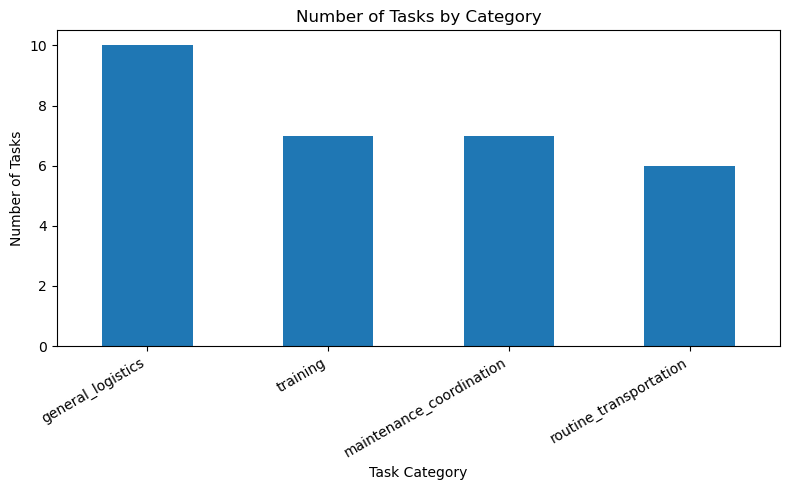

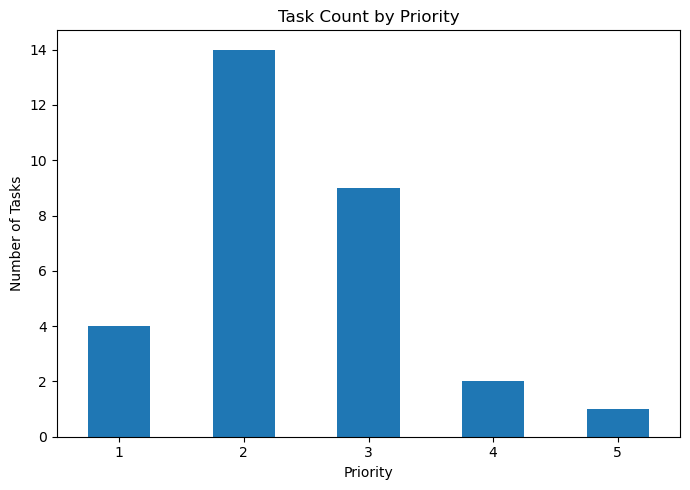

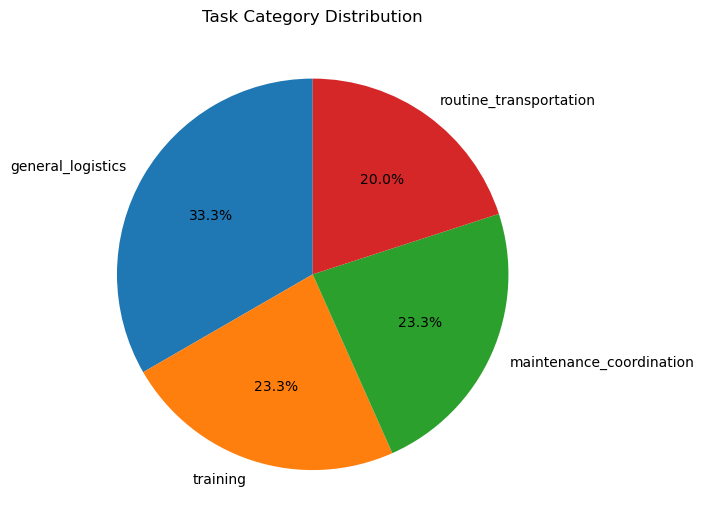

In [27]:
# Count tasks in each category
category_counts = tasks["category"].value_counts()

plt.figure(figsize=(8, 5))
category_counts.plot(kind="bar")
plt.title("Number of Tasks by Category")
plt.xlabel("Task Category")
plt.ylabel("Number of Tasks")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()


# Count tasks at each priority level
priority_counts = tasks["priority"].value_counts().sort_index()

plt.figure(figsize=(7, 5))
priority_counts.plot(kind="bar")
plt.title("Task Count by Priority")
plt.xlabel("Priority")
plt.ylabel("Number of Tasks")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


# Show the proportion of tasks in each category
plt.figure(figsize=(7, 7))
category_counts.plot(kind="pie", autopct="%1.1f%%", startangle=90)
plt.title("Task Category Distribution")
plt.ylabel("")
plt.tight_layout()
plt.show()


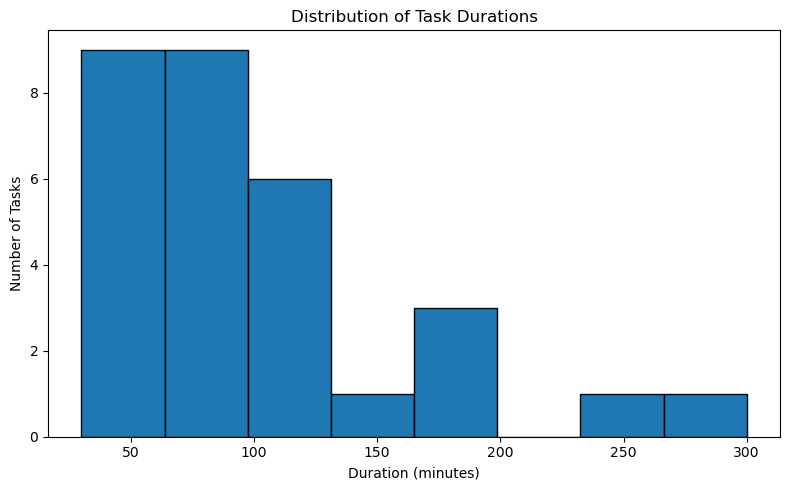

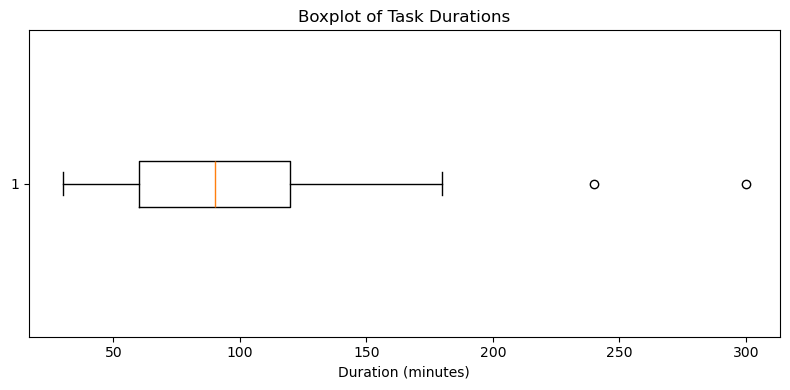

count     30.000000
mean     108.000000
std       59.662846
min       30.000000
25%       60.000000
50%       90.000000
75%      120.000000
max      300.000000
Name: duration_minutes, dtype: float64

In [28]:
# Look at the distribution of task durations
plt.figure(figsize=(8, 5))
plt.hist(tasks["duration_minutes"], bins=8, edgecolor="black")
plt.title("Distribution of Task Durations")
plt.xlabel("Duration (minutes)")
plt.ylabel("Number of Tasks")
plt.tight_layout()
plt.show()


# Check the spread of task durations
plt.figure(figsize=(8, 4))
plt.boxplot(tasks["duration_minutes"], vert=False)
plt.title("Boxplot of Task Durations")
plt.xlabel("Duration (minutes)")
plt.tight_layout()
plt.show()


# Summarize task durations numerically
display(tasks["duration_minutes"].describe())


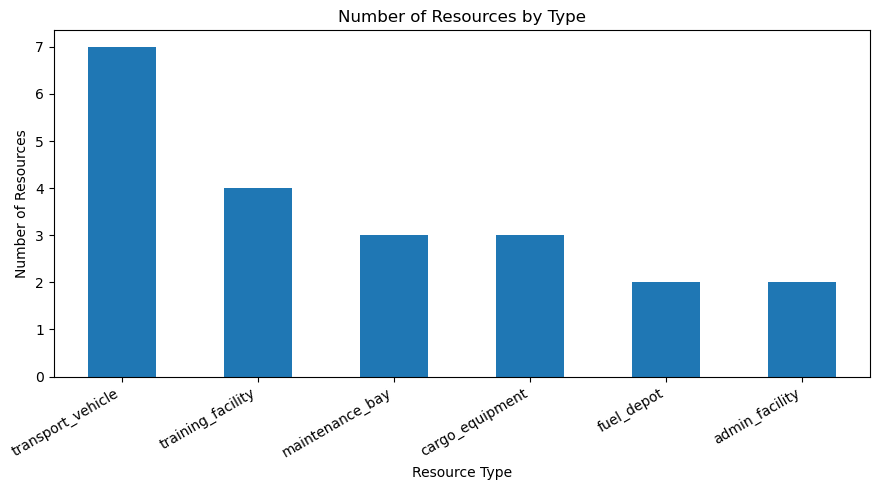

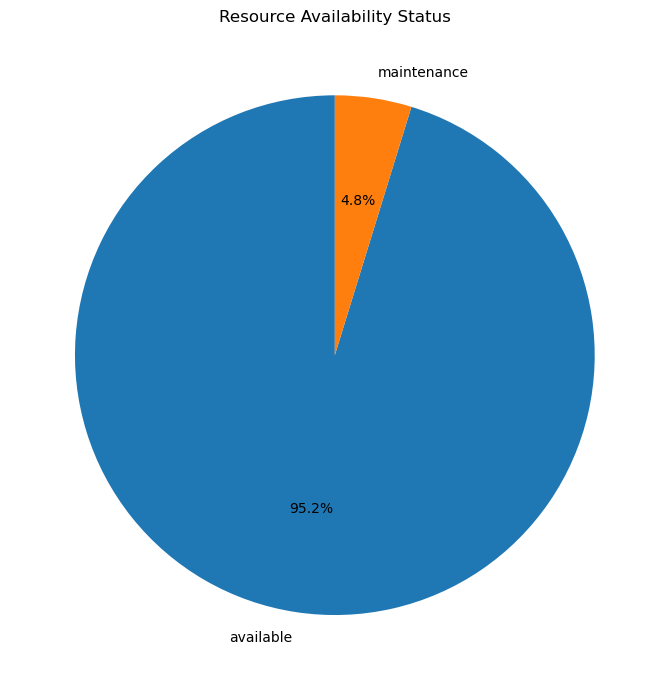

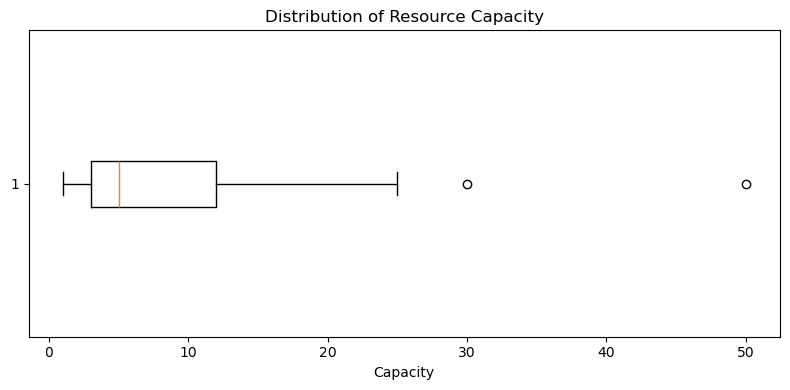

count    21.000000
mean     10.380952
std      12.146918
min       1.000000
25%       3.000000
50%       5.000000
75%      12.000000
max      50.000000
Name: capacity, dtype: float64

In [29]:
# Count resources by type
resource_type_counts = resources["resource_type"].value_counts()

plt.figure(figsize=(9, 5))
resource_type_counts.plot(kind="bar")
plt.title("Number of Resources by Type")
plt.xlabel("Resource Type")
plt.ylabel("Number of Resources")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()


# View resource availability
availability_counts = resources["availability_status"].value_counts()

plt.figure(figsize=(7, 7))
availability_counts.plot(kind="pie", autopct="%1.1f%%", startangle=90)
plt.title("Resource Availability Status")
plt.ylabel("")
plt.tight_layout()
plt.show()


# Examine resource capacities
plt.figure(figsize=(8, 4))
plt.boxplot(resources["capacity"], vert=False)
plt.title("Distribution of Resource Capacity")
plt.xlabel("Capacity")
plt.tight_layout()
plt.show()


# Summarize resource capacity
display(resources["capacity"].describe())

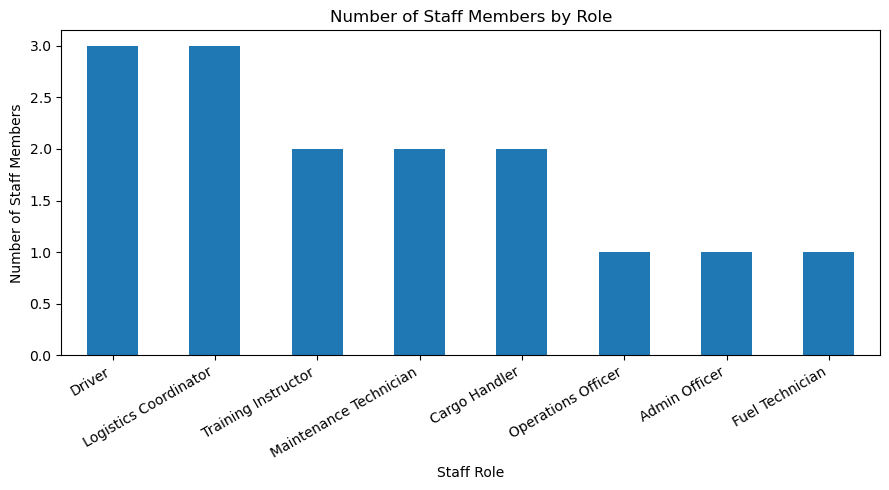

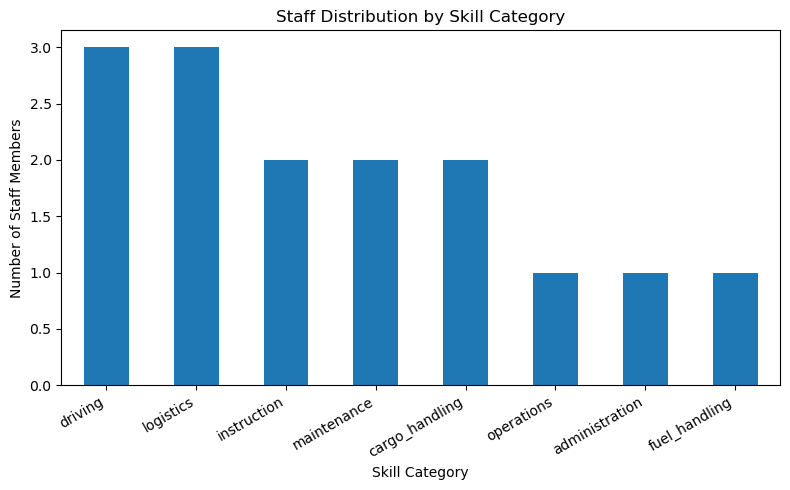

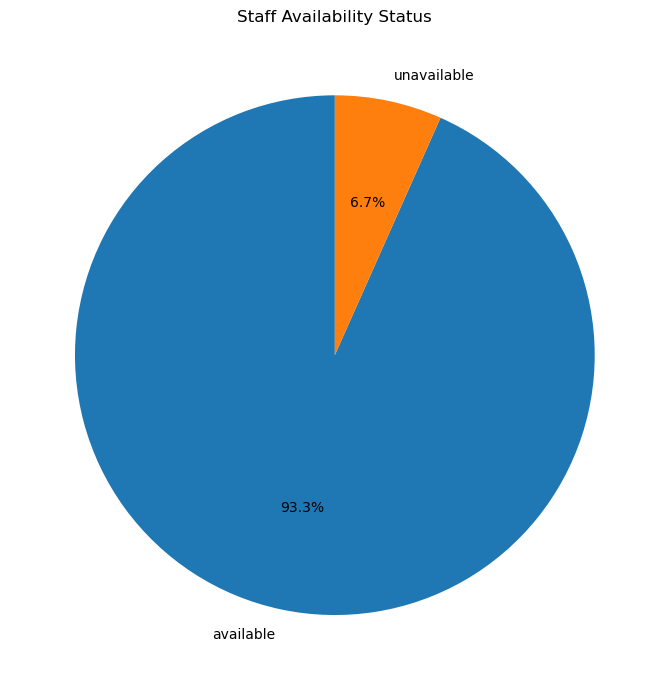

In [30]:
# Count staff members by role
role_counts = staffs["role"].value_counts()

plt.figure(figsize=(9, 5))
role_counts.plot(kind="bar")
plt.title("Number of Staff Members by Role")
plt.xlabel("Staff Role")
plt.ylabel("Number of Staff Members")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()


# Count staff members by skill category
skill_counts = staffs["skill_category"].value_counts()

plt.figure(figsize=(8, 5))
skill_counts.plot(kind="bar")
plt.title("Staff Distribution by Skill Category")
plt.xlabel("Skill Category")
plt.ylabel("Number of Staff Members")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()


# View staff availability
staff_availability = staffs["availability_status"].value_counts()

plt.figure(figsize=(7, 7))
staff_availability.plot(kind="pie", autopct="%1.1f%%", startangle=90)
plt.title("Staff Availability Status")
plt.ylabel("")
plt.tight_layout()
plt.show()

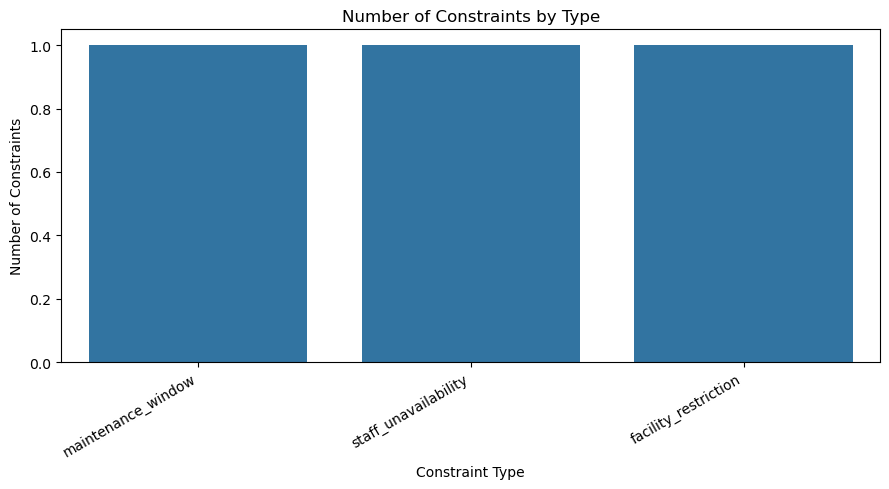

,constraint_id,constraint_type,entity_type,entity_id,start_time,end_time,is_active
0,CON-001,maintenance_window,resource,RES-016,2026-07-13 06:00:00.000000,2026-07-17 06:00:00.000000,1
1,CON-002,staff_unavailability,staff,STF-014,2026-07-12 06:00:00.000000,2026-07-16 06:00:00.000000,1
2,CON-003,facility_restriction,resource,RES-007,2026-07-14 12:00:00.000000,2026-07-14 16:00:00.000000,1


In [31]:
# Count each type of constraint
constraint_counts = constraints["constraint_type"].value_counts()

plt.figure(figsize=(9, 5))
sns.barplot(
    x=constraint_counts.index,
    y=constraint_counts.values
)
plt.title("Number of Constraints by Type")
plt.xlabel("Constraint Type")
plt.ylabel("Number of Constraints")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()


# Display the entities affected by each constraint
display(
    constraints[
        ["constraint_id", "constraint_type", "entity_type",
         "entity_id", "start_time", "end_time", "is_active"]
    ]
)


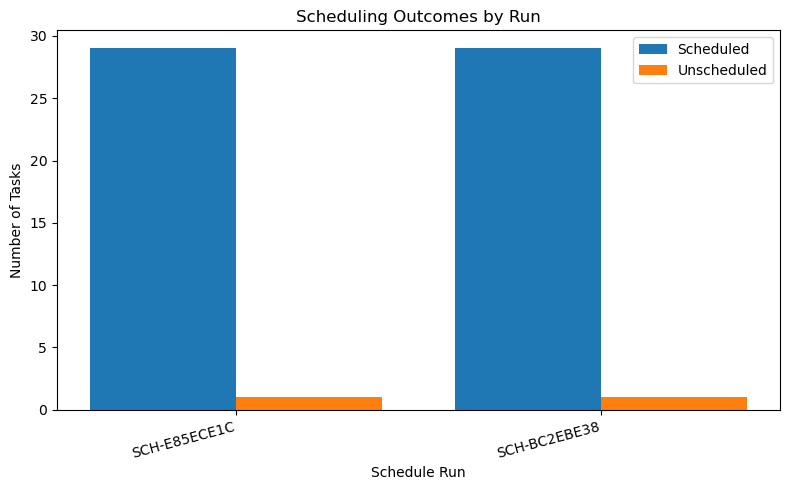

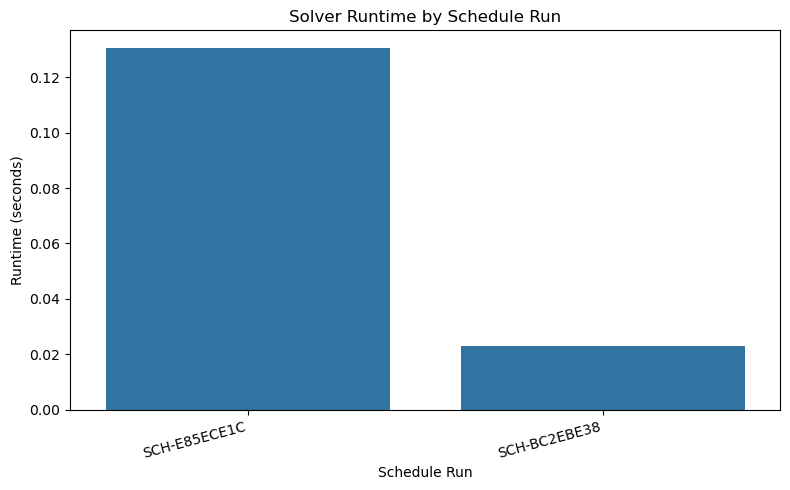

,schedule_id,solver_status,objective_score,runtime_seconds,total_tasks,scheduled_tasks,unscheduled_tasks
0,SCH-E85ECE1C,OPTIMAL,107.0,0.130387,30,29,1
1,SCH-BC2EBE38,OPTIMAL,107.0,0.023001,30,29,1


In [32]:
# Compare scheduled and unscheduled tasks across schedule runs
run_labels = schedule_runs["schedule_id"]

plt.figure(figsize=(8, 5))
x = range(len(schedule_runs))

plt.bar(
    [i - 0.2 for i in x],
    schedule_runs["scheduled_tasks"],
    width=0.4,
    label="Scheduled"
)
plt.bar(
    [i + 0.2 for i in x],
    schedule_runs["unscheduled_tasks"],
    width=0.4,
    label="Unscheduled"
)

plt.xticks(list(x), run_labels, rotation=15, ha="right")
plt.title("Scheduling Outcomes by Run")
plt.xlabel("Schedule Run")
plt.ylabel("Number of Tasks")
plt.legend()
plt.tight_layout()
plt.show()


# Compare solver runtime
plt.figure(figsize=(8, 5))
sns.barplot(
    data=schedule_runs,
    x="schedule_id",
    y="runtime_seconds"
)
plt.title("Solver Runtime by Schedule Run")
plt.xlabel("Schedule Run")
plt.ylabel("Runtime (seconds)")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()


# Inspect the recorded run metrics
display(
    schedule_runs[
        ["schedule_id", "solver_status", "objective_score",
         "runtime_seconds", "total_tasks",
         "scheduled_tasks", "unscheduled_tasks"]
    ]
)


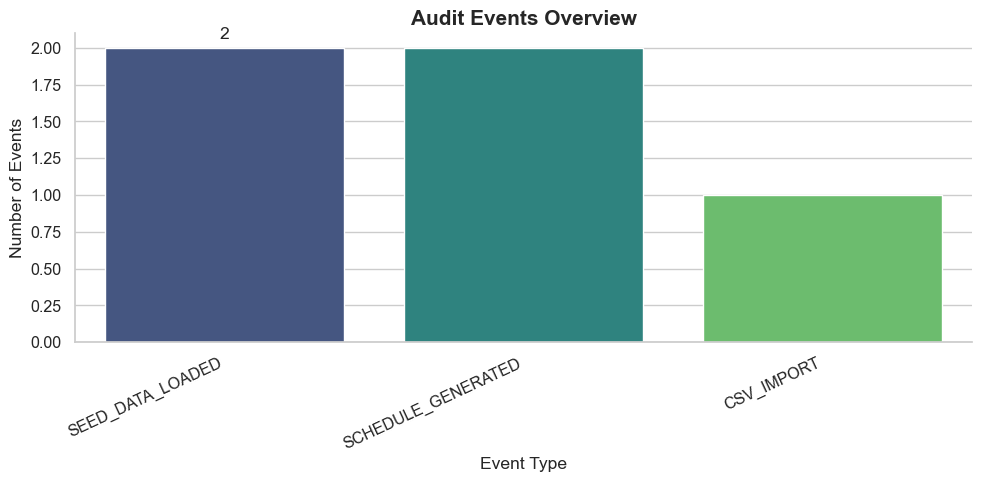

,event_type,entity_type,actor,description,created_at
0,SEED_DATA_LOADED,system,system,"Demo seed data loaded: {'resources': 20, 'staf...",2026-10-10 06:34:56.087683
1,SCHEDULE_GENERATED,schedule,system,Schedule SCH-E85ECE1C generated. Status: OPTIM...,2026-10-10 06:35:12.198805
2,CSV_IMPORT,resources,user,"CSV import: 1 resources imported, 0 skipped",2026-10-10 07:02:00.840550
3,SCHEDULE_GENERATED,schedule,system,Schedule SCH-BC2EBE38 generated. Status: OPTIM...,2026-10-10 07:02:17.861030
4,SEED_DATA_LOADED,system,system,"Demo seed data loaded: {'resources': 0, 'staff...",2026-10-10 07:03:03.814830


In [33]:
sns.set_theme(style="whitegrid", context="notebook", font_scale=1.05)

# Counting audit events
event_counts = audit_logs["event_type"].value_counts()

plt.figure(figsize=(10, 5))

ax = sns.barplot(
    x=event_counts.index,
    y=event_counts.values,
    hue=event_counts.index,
    palette="viridis",
    legend=False
)

ax.bar_label(ax.containers[0], padding=4)
ax.set_title("Audit Events Overview", fontsize=15, fontweight="bold")
ax.set_xlabel("Event Type")
ax.set_ylabel("Number of Events")
plt.xticks(rotation=25, ha="right")
sns.despine()
plt.tight_layout()
plt.show()

# Inspecting the logged events
display(
    audit_logs[
        ["event_type", "entity_type", "actor", "description", "created_at"]
    ]
)

## Missing val (heatmap)

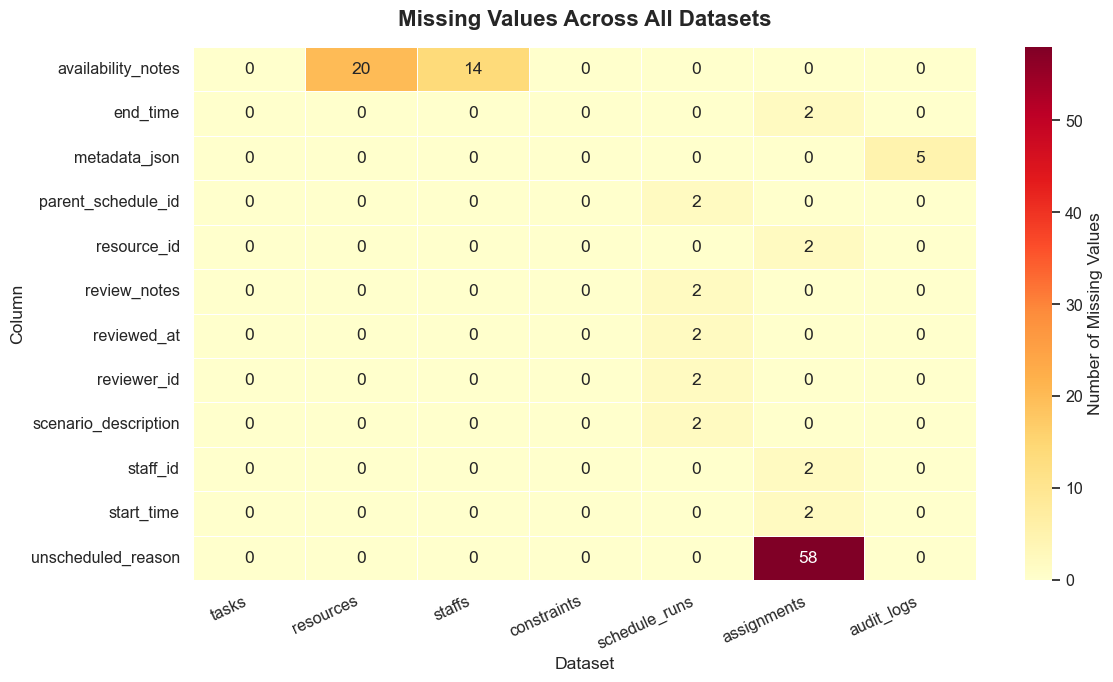

In [35]:
# Collect the number of missing values in each column
missing_data = pd.DataFrame({
    name: df.isnull().sum()
    for name, df in datasets.items()
})

# Replace missing counts with zero where a dataset has no such column
missing_data = missing_data.fillna(0).astype(int)

# Keep only columns that contain at least one missing value
missing_data = missing_data.loc[
    missing_data.sum(axis=1) > 0
]

plt.figure(figsize=(12, 7))

sns.heatmap(
    missing_data,
    annot=True,
    fmt="d",
    cmap="YlOrRd",
    linewidths=0.5,
    cbar_kws={"label": "Number of Missing Values"}
)

plt.title(
    "Missing Values Across All Datasets",
    fontsize=16,
    fontweight="bold",
    pad=15
)
plt.xlabel("Dataset")
plt.ylabel("Column")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

In [36]:
# Inspecting missing values without changing the original data
for name, df in datasets.items():
    missing_counts = df.isnull().sum()
    missing_counts = missing_counts[missing_counts > 0]

    print(f"\n{'=' * 55}")
    print(f"Dataset: {name}")
    print(f"{'=' * 55}")

    if missing_counts.empty:
        print("No missing values.")
        continue

    report = pd.DataFrame({
        "missing_count": missing_counts,
        "missing_percent": (
            missing_counts / len(df) * 100
        ).round(2)
    })

    display(report)

    # Show the actual records containing missing values
    missing_rows = df[df.isnull().any(axis=1)]
    display(missing_rows)



Dataset: tasks
No missing values.

Dataset: resources


,missing_count,missing_percent
availability_notes,20,95.24


,id,resource_id,name,resource_type,capacity,availability_status,maintenance_status,availability_notes,is_active,created_at,updated_at
0,1,RES-001,Transport Truck Alpha,transport_vehicle,10,available,operational,NaN,1,2026-10-10 06:34:56.091847,2026-10-10 06:34:56.091847
1,2,RES-002,Transport Truck Bravo,transport_vehicle,10,available,operational,NaN,1,2026-10-10 06:34:56.091847,2026-10-10 06:34:56.091847
2,3,RES-003,Transport Truck Charlie,transport_vehicle,8,available,operational,NaN,1,2026-10-10 06:34:56.091847,2026-10-10 06:34:56.091847
3,4,RES-004,Logistics Van Delta,transport_vehicle,4,available,operational,NaN,1,2026-10-10 06:34:56.091847,2026-10-10 06:34:56.091847
4,5,RES-005,Training Hall A,training_facility,30,available,operational,NaN,1,2026-10-10 06:34:56.091847,2026-10-10 06:34:56.091847
5,6,RES-006,Training Hall B,training_facility,25,available,operational,NaN,1,2026-10-10 06:34:56.091847,2026-10-10 06:34:56.091847
6,7,RES-007,Simulation Lab 1,training_facility,15,available,operational,NaN,1,2026-10-10 06:34:56.091847,2026-10-10 06:34:56.091847
7,8,RES-008,Maintenance Bay 1,maintenance_bay,2,available,operational,NaN,1,2026-10-10 06:34:56.091847,2026-10-10 06:34:56.091847
8,9,RES-009,Maintenance Bay 2,maintenance_bay,2,available,operational,NaN,1,2026-10-10 06:34:56.091847,2026-10-10 06:34:56.091847
9,10,RES-010,Fuel Depot North,fuel_depot,5,available,operational,NaN,1,2026-10-10 06:34:56.091847,2026-10-10 06:34:56.091847



Dataset: staffs


,missing_count,missing_percent
availability_notes,14,93.33


...

,missing_count,missing_percent
resource_id,2,3.33
staff_id,2,3.33
start_time,2,3.33
end_time,2,3.33
unscheduled_reason,58,96.67


,id,schedule_run_id,task_id,resource_id,staff_id,start_time,end_time,is_scheduled,unscheduled_reason,explanation,created_at
0,1,1,TSK-001,RES-005,STF-006,2026-07-14 06:00:00.000000,2026-07-14 08:00:00.000000,1,NaN,Scheduled from 2026-07-14 06:00 to 2026-07-14 ...,2026-10-10 06:35:12.199804
1,2,1,TSK-002,RES-006,STF-005,2026-07-14 06:00:00.000000,2026-07-14 07:30:00.000000,1,NaN,Scheduled from 2026-07-14 06:00 to 2026-07-14 ...,2026-10-10 06:35:12.199804
2,3,1,TSK-003,RES-005,STF-005,2026-07-14 08:00:00.000000,2026-07-14 11:00:00.000000,1,NaN,Scheduled from 2026-07-14 08:00 to 2026-07-14 ...,2026-10-10 06:35:12.199804
3,4,1,TSK-004,RES-006,STF-005,2026-07-14 11:00:00.000000,2026-07-14 12:00:00.000000,1,NaN,Scheduled from 2026-07-14 11:00 to 2026-07-14 ...,2026-10-10 06:35:12.199804
4,5,1,TSK-005,RES-007,STF-006,2026-07-14 12:00:00.000000,2026-07-14 13:30:00.000000,1,NaN,Scheduled from 2026-07-14 12:00 to 2026-07-14 ...,2026-10-10 06:35:12.199804
5,6,1,TSK-006,RES-001,STF-001,2026-07-14 08:45:00.000000,2026-07-14 11:15:00.000000,1,NaN,Scheduled from 2026-07-14 08:45 to 2026-07-14 ...,2026-10-10 06:35:12.199804
6,7,1,TSK-007,RES-001,STF-001,2026-07-14 12:45:00.000000,2026-07-14 13:45:00.000000,1,NaN,Scheduled from 2026-07-14 12:45 to 2026-07-14 ...,2026-10-10 06:35:12.199804
7,8,1,TSK-008,RES-001,STF-001,2026-07-14 13:45:00.000000,2026-07-14 15:15:00.000000,1,NaN,Scheduled from 2026-07-14 13:45 to 2026-07-14 ...,2026-10-10 06:35:12.199804
8,9,1,TSK-009,RES-001,STF-001,2026-07-14 06:00:00.000000,2026-07-14 08:00:00.000000,1,NaN,Scheduled from 2026-07-14 06:00 to 2026-07-14 ...,2026-10-10 06:35:12.199804
9,10,1,TSK-010,RES-001,STF-001,2026-07-14 08:00:00.000000,2026-07-14 08:45:00.000000,1,NaN,Scheduled from 2026-07-14 08:00 to 2026-07-14 ...,2026-10-10 06:35:12.199804



Dataset: audit_logs


,missing_count,missing_percent
metadata_json,5,100.0


,id,event_type,entity_type,entity_id,actor,description,metadata_json,created_at
0,1,SEED_DATA_LOADED,system,system,system,"Demo seed data loaded: {'resources': 20, 'staf...",NaN,2026-10-10 06:34:56.087683
1,2,SCHEDULE_GENERATED,schedule,SCH-E85ECE1C,system,Schedule SCH-E85ECE1C generated. Status: OPTIM...,NaN,2026-10-10 06:35:12.198805
2,3,CSV_IMPORT,resources,bulk,user,"CSV import: 1 resources imported, 0 skipped",NaN,2026-10-10 07:02:00.840550
3,4,SCHEDULE_GENERATED,schedule,SCH-BC2EBE38,system,Schedule SCH-BC2EBE38 generated. Status: OPTIM...,NaN,2026-10-10 07:02:17.861030
4,5,SEED_DATA_LOADED,system,system,system,"Demo seed data loaded: {'resources': 0, 'staff...",NaN,2026-10-10 07:03:03.814830


In [37]:
# Inspecting feature variety without modifying any dataset
for name, df in datasets.items():
    print(f"\n{'=' * 50}")
    print(f"Dataset: {name}")
    print(f"{'=' * 50}")

    summary = pd.DataFrame({
        "data_type": df.dtypes.astype(str),
        "unique_non_missing": df.nunique(dropna=True),
        "missing_count": df.isnull().sum()
    })

    display(summary)



Dataset: tasks


,data_type,unique_non_missing,missing_count
id,int64,30,0
task_id,object,30,0
title,object,30,0
category,object,4,0
description,object,30,0
duration_minutes,int64,9,0
priority,int64,5,0
earliest_start,object,6,0
deadline,object,10,0
required_resource_type,object,6,0



Dataset: resources


,data_type,unique_non_missing,missing_count
id,int64,21,0
resource_id,object,21,0
name,object,21,0
resource_type,object,6,0
capacity,int64,14,0
availability_status,object,2,0
maintenance_status,object,2,0
availability_notes,object,1,20
is_active,int64,1,0
created_at,object,2,0



Dataset: staffs


...

,data_type,unique_non_missing,missing_count
id,int64,2,0
schedule_id,object,2,0
version,int64,1,0
status,object,1,0
solver_status,object,1,0
objective_score,float64,1,0
runtime_seconds,float64,2,0
total_tasks,int64,1,0
scheduled_tasks,int64,1,0
unscheduled_tasks,int64,1,0



Dataset: assignments


,data_type,unique_non_missing,missing_count
id,int64,60,0
schedule_run_id,int64,2,0
task_id,object,30,0
resource_id,object,11,2
staff_id,object,9,2
start_time,object,15,2
end_time,object,17,2
is_scheduled,int64,2,0
unscheduled_reason,object,1,58
explanation,object,33,0



Dataset: audit_logs


,data_type,unique_non_missing,missing_count
id,int64,5,0
event_type,object,3,0
entity_type,object,3,0
entity_id,object,4,0
actor,object,2,0
description,object,5,0
metadata_json,float64,0,5
created_at,object,5,0


## Analyzing target distribution

In [39]:
print("Assignment target distribution:")
display(
    assignments["is_scheduled"]
    .value_counts(dropna=False)
    .rename_axis("is_scheduled")
    .reset_index(name="count")
)

print("\nUnique tasks per target class:")
display(
    assignments.groupby("is_scheduled")["task_id"]
    .nunique()
    .rename("unique_tasks")
    .reset_index()
)
# to Check whether task-level status agrees with assignment outcomes
status_check = assignments.merge(
    tasks[["task_id", "scheduling_status"]],
    on="task_id",
    how="left"
)

print("\nTask status versus assignment outcome:")
display(
    pd.crosstab(
        status_check["scheduling_status"],
        status_check["is_scheduled"],
        margins=True
    )
)

# it Show the task IDs associated with each target class
print("\nTasks by assignment outcome:")
display(
    assignments.groupby("is_scheduled")["task_id"]
    .agg(lambda values: sorted(values.unique().tolist()))
    .reset_index()
)


Assignment target distribution:


,is_scheduled,count
0,1,58
1,0,2



Unique tasks per target class:


,is_scheduled,unique_tasks
0,0,1
1,1,29



Task status versus assignment outcome:


is_scheduled,0,1,All
scheduling_status,,,
unscheduled,2,58,60
All,2,58,60



Tasks by assignment outcome:


,is_scheduled,task_id
0,0,[TSK-025]
1,1,"[TSK-001, TSK-002, TSK-003, TSK-004, TSK-005, ..."


In [40]:
# Summarize outcomes per unique task without modifying the source data
task_outcomes = (
    assignments.groupby("task_id")
    .agg(
        number_of_runs=("schedule_run_id", "nunique"),
        observed_outcomes=("is_scheduled", "nunique"),
        scheduled_rows=("is_scheduled", "sum")
    )
    .reset_index()
)

task_outcomes = task_outcomes.merge(
    tasks[["task_id", "scheduling_status"]],
    on="task_id",
    how="left"
)

print("Number of unique tasks:", task_outcomes["task_id"].nunique())

print("\nTasks with inconsistent outcomes across runs:")
display(
    task_outcomes[task_outcomes["observed_outcomes"] > 1]
)

print("\nTask-level outcome summary:")
display(
    task_outcomes[
        ["task_id", "number_of_runs", "scheduled_rows",
         "scheduling_status"]
    ].sort_values("task_id")
)


Number of unique tasks: 30

Tasks with inconsistent outcomes across runs:


,task_id,number_of_runs,observed_outcomes,scheduled_rows,scheduling_status



Task-level outcome summary:


,task_id,number_of_runs,scheduled_rows,scheduling_status
0,TSK-001,2,2,unscheduled
1,TSK-002,2,2,unscheduled
2,TSK-003,2,2,unscheduled
3,TSK-004,2,2,unscheduled
4,TSK-005,2,2,unscheduled
5,TSK-006,2,2,unscheduled
6,TSK-007,2,2,unscheduled
7,TSK-008,2,2,unscheduled
8,TSK-009,2,2,unscheduled
9,TSK-010,2,2,unscheduled


In [41]:

# Build one row per task from the original task table
model_data = tasks.copy()

# Derive the observed outcome from the assignment records
# First verify that every task has exactly one consistent outcome
outcome_counts = assignments.groupby("task_id")["is_scheduled"].nunique()

if not outcome_counts.eq(1).all():
    raise ValueError(
        "Some tasks have conflicting outcomes; resolve them before proceeding."
    )

task_labels = (
    assignments.groupby("task_id")["is_scheduled"]
    .first()
    .rename("target_scheduled")
    .reset_index()
)

model_data = model_data.merge(
    task_labels,
    on="task_id",
    how="left",
    validate="one_to_one"
)

# Inspect the modelling table and target distribution
print("Modelling table shape:", model_data.shape)

display(
    model_data[
        [
            "task_id",
            "category",
            "duration_minutes",
            "priority",
            "required_resource_type",
            "required_skill",
            "target_scheduled"
        ]
    ].head(10)
)

print("\nTarget distribution:")
display(
    model_data["target_scheduled"]
    .value_counts()
    .sort_index()
    .rename_axis("target_scheduled")
    .reset_index(name="count")
)


Modelling table shape: (30, 16)


,task_id,category,duration_minutes,priority,required_resource_type,required_skill,target_scheduled
0,TSK-001,training,120,2,training_facility,instruction,1
1,TSK-002,training,90,2,training_facility,instruction,1
2,TSK-003,training,180,3,training_facility,instruction,1
3,TSK-004,training,60,1,training_facility,instruction,1
4,TSK-005,training,90,2,training_facility,instruction,1
5,TSK-006,routine_transportation,150,2,transport_vehicle,driving,1
6,TSK-007,routine_transportation,60,3,transport_vehicle,driving,1
7,TSK-008,routine_transportation,90,3,transport_vehicle,driving,1
8,TSK-009,routine_transportation,120,2,transport_vehicle,driving,1
9,TSK-010,routine_transportation,45,1,transport_vehicle,driving,1



Target distribution:


,target_scheduled,count
0,0,1
1,1,29


## Combined dataset (required col)

In [43]:
model_data.to_csv("model_data.csv")

## Summary of the dataset

In [45]:
model_data.describe()

,id,duration_minutes,priority,is_active,target_scheduled
count,30.000000,30.000000,30.000000,30.0,30.000000
mean,15.500000,108.000000,2.400000,1.0,0.966667
std,8.803408,59.662846,0.932183,0.0,0.182574
min,1.000000,30.000000,1.000000,1.0,0.000000
25%,8.250000,60.000000,2.000000,1.0,1.000000
50%,15.500000,90.000000,2.000000,1.0,1.000000
75%,22.750000,120.000000,3.000000,1.0,1.000000
max,30.000000,300.000000,5.000000,1.0,1.000000


## Checking data types

In [47]:
model_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 16 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   id                      30 non-null     int64 
 1   task_id                 30 non-null     object
 2   title                   30 non-null     object
 3   category                30 non-null     object
 4   description             30 non-null     object
 5   duration_minutes        30 non-null     int64 
 6   priority                30 non-null     int64 
 7   earliest_start          30 non-null     object
 8   deadline                30 non-null     object
 9   required_resource_type  30 non-null     object
 10  required_skill          30 non-null     object
 11  scheduling_status       30 non-null     object
 12  is_active               30 non-null     int64 
 13  created_at              30 non-null     object
 14  updated_at              30 non-null     object
 15  target_s

## Checking for null values

In [49]:
model_data.isnull().sum()

id                        0
task_id                   0
title                     0
category                  0
description               0
duration_minutes          0
priority                  0
earliest_start            0
deadline                  0
required_resource_type    0
required_skill            0
scheduling_status         0
is_active                 0
created_at                0
updated_at                0
target_scheduled          0
dtype: int64

## Checking duplicate

In [51]:
model_data.duplicated().sum()

0

## Model building

In [53]:
# Select input features
feature_columns = [
    "category",
    "duration_minutes",
    "priority",
    "required_resource_type",
    "required_skill"
]

X = model_data[feature_columns].copy()
y = model_data["target_scheduled"].copy()

print("Feature dataset shape:", X.shape)
print("Target dataset shape:", y.shape)

print("\nFeature data types:")
display(X.dtypes.to_frame(name="data_type"))

print("\nTarget distribution:")
display(y.value_counts().sort_index().to_frame(name="count"))

Feature dataset shape: (30, 5)
Target dataset shape: (30,)

Feature data types:


,data_type
category,object
duration_minutes,int64
priority,int64
required_resource_type,object
required_skill,object



Target distribution:


,count
target_scheduled,
0,1
1,29


## Data Pre-processing - OneHotEncoder

In [55]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

# Separate numerical and categorical features
numeric_features = [
    "duration_minutes",
    "priority"
]

categorical_features = [
    "category",
    "required_resource_type",
    "required_skill"
]

# Creating the preprocessing step
preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        ),
        (
            "numerical",
            "passthrough",
            numeric_features
        )
    ]
)

# Transform the feature data for inspection
X_encoded = preprocessor.fit_transform(X)

print("Original feature shape:", X.shape)
print("Encoded feature shape:", X_encoded.shape)

print("\nEncoded feature names:")
print(preprocessor.get_feature_names_out())

Original feature shape: (30, 5)
Encoded feature shape: (30, 19)

Encoded feature names:
['categorical__category_general_logistics'
 'categorical__category_maintenance_coordination'
 'categorical__category_routine_transportation'
 'categorical__category_training'
 'categorical__required_resource_type_admin_facility'
 'categorical__required_resource_type_cargo_equipment'
 'categorical__required_resource_type_fuel_depot'
 'categorical__required_resource_type_maintenance_bay'
 'categorical__required_resource_type_training_facility'
 'categorical__required_resource_type_transport_vehicle'
 'categorical__required_skill_administration'
 'categorical__required_skill_cargo_handling'
 'categorical__required_skill_driving'
 'categorical__required_skill_fuel_handling'
 'categorical__required_skill_instruction'
 'categorical__required_skill_logistics'
 'categorical__required_skill_maintenance' 'numerical__duration_minutes'
 'numerical__priority']


In [56]:
# Inspecting the modelling dataset
print("Column names:")
print(model_data.columns.tolist())

print("\nDataset information:")
model_data.info()

print("\nFirst five rows:")
display(model_data.head())

print("\nTarget distribution:")
display(
    model_data["target_scheduled"]
    .value_counts()
    .sort_index()
    .rename_axis("target_scheduled")
    .reset_index(name="count")
)

Column names:
['id', 'task_id', 'title', 'category', 'description', 'duration_minutes', 'priority', 'earliest_start', 'deadline', 'required_resource_type', 'required_skill', 'scheduling_status', 'is_active', 'created_at', 'updated_at', 'target_scheduled']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 16 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   id                      30 non-null     int64 
 1   task_id                 30 non-null     object
 2   title                   30 non-null     object
 3   category                30 non-null     object
 4   description             30 non-null     object
 5   duration_minutes        30 non-null     int64 
 6   priority                30 non-null     int64 
 7   earliest_start          30 non-null     object
 8   deadline                30 non-null     object
 9   required_resource_type  30 non-null     ob

,id,task_id,title,category,description,duration_minutes,priority,earliest_start,deadline,required_resource_type,required_skill,scheduling_status,is_active,created_at,updated_at,target_scheduled
0,1,TSK-001,Basic Logistics Orientation,training,Introductory training for new logistics personnel,120,2,2026-07-14 06:00:00.000000,2026-07-14 14:00:00.000000,training_facility,instruction,unscheduled,1,2026-10-10 06:34:56.093927,2026-10-10 06:34:56.093927,1
1,2,TSK-002,Vehicle Safety Refresher,training,Annual vehicle safety refresher course,90,2,2026-07-14 06:00:00.000000,2026-07-14 16:00:00.000000,training_facility,instruction,unscheduled,1,2026-10-10 06:34:56.093927,2026-10-10 06:34:56.093927,1
2,3,TSK-003,Cargo Handling Certification,training,Certification training for cargo handlers,180,3,2026-07-14 08:00:00.000000,2026-07-14 18:00:00.000000,training_facility,instruction,unscheduled,1,2026-10-10 06:34:56.093927,2026-10-10 06:34:56.093927,1
3,4,TSK-004,Emergency Procedures Drill,training,Quarterly emergency procedures drill,60,1,2026-07-14 06:00:00.000000,2026-07-14 12:00:00.000000,training_facility,instruction,unscheduled,1,2026-10-10 06:34:56.093927,2026-10-10 06:34:56.093927,1
4,5,TSK-005,Fuel Handling Safety Training,training,Safety training for fuel depot personnel,90,2,2026-07-14 10:00:00.000000,2026-07-14 20:00:00.000000,training_facility,instruction,unscheduled,1,2026-10-10 06:34:56.093927,2026-10-10 06:34:56.093927,1



Target distribution:


,target_scheduled,count
0,0,1
1,1,29


## Train-test split

In [58]:
from sklearn.model_selection import train_test_split

# Check how many unique tasks belong to each class
print("Target counts:")
print(y.value_counts().sort_index())

print("\nTarget proportions:")
print(y.value_counts(normalize=True).sort_index().round(3))

# Inspect the class counts expected in an 80/20 split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("\nTraining set size:", len(X_train))
print("Testing set size:", len(X_test))

print("\nTraining target distribution:")
print(y_train.value_counts().sort_index())

print("\nTesting target distribution:")
print(y_test.value_counts().sort_index())

Target counts:
target_scheduled
0     1
1    29
Name: count, dtype: int64

Target proportions:
target_scheduled
0    0.033
1    0.967
Name: proportion, dtype: float64

Training set size: 24
Testing set size: 6

Training target distribution:
target_scheduled
0     1
1    23
Name: count, dtype: int64

Testing target distribution:
target_scheduled
1    6
Name: count, dtype: int64


In [59]:
# Comparing the outcomes for each task across schedule runs
outcome_check = (
    assignments
    .pivot_table(
        index="task_id",
        columns="schedule_run_id",
        values="is_scheduled",
        aggfunc="first"
    )
)
print("Task outcomes across schedule runs:")
display(outcome_check)
print("\nNumber of unique tasks:", assignments["task_id"].nunique())
print("\nOutcome changes between runs:")
if outcome_check.shape[1] >= 2:
    changed = outcome_check.iloc[:, 0] != outcome_check.iloc[:, 1]
    print("Tasks with different outcomes:", changed.sum())
    display(outcome_check[changed])
else:
    print("Not enough schedule runs to compare.")

Task outcomes across schedule runs:


schedule_run_id,1,2
task_id,,
TSK-001,1,1
TSK-002,1,1
TSK-003,1,1
TSK-004,1,1
TSK-005,1,1
TSK-006,1,1
TSK-007,1,1
TSK-008,1,1
TSK-009,1,1



Number of unique tasks: 30

Outcome changes between runs:
Tasks with different outcomes: 0


schedule_run_id,1,2
task_id,,


In [60]:
# Inspecting the columns and sample rows of relevant datasets

for name in ["tasks", "assignments", "constraints", "resources", "staffs", "schedule_runs"]:
    df = datasets[name]

    print(f"\n{'=' * 50}")
    print(f"Dataset: {name}")
    print("Shape:", df.shape)
    print("Columns:", df.columns.tolist())

    display(df.head(3))


Dataset: tasks
Shape: (30, 15)
Columns: ['id', 'task_id', 'title', 'category', 'description', 'duration_minutes', 'priority', 'earliest_start', 'deadline', 'required_resource_type', 'required_skill', 'scheduling_status', 'is_active', 'created_at', 'updated_at']


,id,task_id,title,category,description,duration_minutes,priority,earliest_start,deadline,required_resource_type,required_skill,scheduling_status,is_active,created_at,updated_at
0,1,TSK-001,Basic Logistics Orientation,training,Introductory training for new logistics personnel,120,2,2026-07-14 06:00:00.000000,2026-07-14 14:00:00.000000,training_facility,instruction,unscheduled,1,2026-10-10 06:34:56.093927,2026-10-10 06:34:56.093927
1,2,TSK-002,Vehicle Safety Refresher,training,Annual vehicle safety refresher course,90,2,2026-07-14 06:00:00.000000,2026-07-14 16:00:00.000000,training_facility,instruction,unscheduled,1,2026-10-10 06:34:56.093927,2026-10-10 06:34:56.093927
2,3,TSK-003,Cargo Handling Certification,training,Certification training for cargo handlers,180,3,2026-07-14 08:00:00.000000,2026-07-14 18:00:00.000000,training_facility,instruction,unscheduled,1,2026-10-10 06:34:56.093927,2026-10-10 06:34:56.093927



Dataset: assignments
Shape: (60, 11)
Columns: ['id', 'schedule_run_id', 'task_id', 'resource_id', 'staff_id', 'start_time', 'end_time', 'is_scheduled', 'unscheduled_reason', 'explanation', 'created_at']


,id,schedule_run_id,task_id,resource_id,staff_id,start_time,end_time,is_scheduled,unscheduled_reason,explanation,created_at
0,1,1,TSK-001,RES-005,STF-006,2026-07-14 06:00:00.000000,2026-07-14 08:00:00.000000,1,NaN,Scheduled from 2026-07-14 06:00 to 2026-07-14 ...,2026-10-10 06:35:12.199804
1,2,1,TSK-002,RES-006,STF-005,2026-07-14 06:00:00.000000,2026-07-14 07:30:00.000000,1,NaN,Scheduled from 2026-07-14 06:00 to 2026-07-14 ...,2026-10-10 06:35:12.199804
2,3,1,TSK-003,RES-005,STF-005,2026-07-14 08:00:00.000000,2026-07-14 11:00:00.000000,1,NaN,Scheduled from 2026-07-14 08:00 to 2026-07-14 ...,2026-10-10 06:35:12.199804



Dataset: constraints
Shape: (3, 11)
Columns: ['id', 'constraint_id', 'constraint_type', 'entity_type', 'entity_id', 'start_time', 'end_time', 'reason', 'is_active', 'created_at', 'updated_at']


...

,id,resource_id,name,resource_type,capacity,availability_status,maintenance_status,availability_notes,is_active,created_at,updated_at
0,1,RES-001,Transport Truck Alpha,transport_vehicle,10,available,operational,NaN,1,2026-10-10 06:34:56.091847,2026-10-10 06:34:56.091847
1,2,RES-002,Transport Truck Bravo,transport_vehicle,10,available,operational,NaN,1,2026-10-10 06:34:56.091847,2026-10-10 06:34:56.091847
2,3,RES-003,Transport Truck Charlie,transport_vehicle,8,available,operational,NaN,1,2026-10-10 06:34:56.091847,2026-10-10 06:34:56.091847



Dataset: staffs
Shape: (15, 10)
Columns: ['id', 'staff_id', 'name', 'role', 'skill_category', 'availability_status', 'availability_notes', 'is_active', 'created_at', 'updated_at']


,id,staff_id,name,role,skill_category,availability_status,availability_notes,is_active,created_at,updated_at
0,1,STF-001,Cpl. Arjun Mehta,Driver,driving,available,NaN,1,2026-10-10 06:34:56.092844,2026-10-10 06:34:56.092844
1,2,STF-002,Cpl. Priya Sharma,Driver,driving,available,NaN,1,2026-10-10 06:34:56.092844,2026-10-10 06:34:56.092844
2,3,STF-003,Sgt. Ravi Kumar,Logistics Coordinator,logistics,available,NaN,1,2026-10-10 06:34:56.092844,2026-10-10 06:34:56.092844



Dataset: schedule_runs
Shape: (2, 17)
Columns: ['id', 'schedule_id', 'version', 'status', 'solver_status', 'objective_score', 'runtime_seconds', 'total_tasks', 'scheduled_tasks', 'unscheduled_tasks', 'scenario_description', 'parent_schedule_id', 'reviewer_id', 'review_notes', 'reviewed_at', 'created_at', 'updated_at']


,id,schedule_id,version,status,solver_status,objective_score,runtime_seconds,total_tasks,scheduled_tasks,unscheduled_tasks,scenario_description,parent_schedule_id,reviewer_id,review_notes,reviewed_at,created_at,updated_at
0,1,SCH-E85ECE1C,1,PENDING_REVIEW,OPTIMAL,107.0,0.130387,30,29,1,NaN,NaN,NaN,NaN,NaN,2026-10-10 06:35:12.196892,2026-10-10 06:35:12.196892
1,2,SCH-BC2EBE38,1,PENDING_REVIEW,OPTIMAL,107.0,0.023001,30,29,1,NaN,NaN,NaN,NaN,NaN,2026-10-10 07:02:17.849980,2026-10-10 07:02:17.849980


In [61]:
# Inspecting the task that was unscheduled in both schedule runs
unscheduled_ids = assignments.loc[
    assignments["is_scheduled"].eq(0),
    "task_id"
].unique()

print("Unscheduled task IDs:", unscheduled_ids)

print("\nTask details:")
display(
    tasks.loc[
        tasks["task_id"].isin(unscheduled_ids)
    ]
)

print("\nAssignment records:")
display(
    assignments.loc[
        assignments["task_id"].isin(unscheduled_ids),
        [
            "schedule_run_id",
            "task_id",
            "resource_id",
            "staff_id",
            "start_time",
            "end_time",
            "is_scheduled",
            "unscheduled_reason",
            "explanation"
        ]
    ]
)

Unscheduled task IDs: ['TSK-025']

Task details:


,id,task_id,title,category,description,duration_minutes,priority,earliest_start,deadline,required_resource_type,required_skill,scheduling_status,is_active,created_at,updated_at
24,25,TSK-025,Impossible Quick Turnaround,maintenance_coordination,Infeasible: 300-minute task with only 60-minut...,300,5,2026-07-14 06:00:00.000000,2026-07-14 07:00:00.000000,maintenance_bay,maintenance,unscheduled,1,2026-10-10 06:34:56.093927,2026-10-10 06:34:56.093927



Assignment records:


,schedule_run_id,task_id,resource_id,staff_id,start_time,end_time,is_scheduled,unscheduled_reason,explanation
24,1,TSK-025,NaN,NaN,NaN,NaN,0,Task deadline is too tight for its duration,Hard constraint violation: Task deadline is to...
54,2,TSK-025,NaN,NaN,NaN,NaN,0,Task deadline is too tight for its duration,Hard constraint violation: Task deadline is to...


In [62]:
# Create a separate task-window analysis table
task_window_analysis = model_data[
    [
        "task_id",
        "duration_minutes",
        "earliest_start",
        "deadline",
        "target_scheduled"
    ]
].copy()

# Convert timestamps for calculation only
task_window_analysis["earliest_start"] = pd.to_datetime(
    task_window_analysis["earliest_start"],
    errors="coerce"
)

task_window_analysis["deadline"] = pd.to_datetime(
    task_window_analysis["deadline"],
    errors="coerce"
)

# Calculate the available window in minutes
task_window_analysis["available_window_minutes"] = (
    task_window_analysis["deadline"]
    - task_window_analysis["earliest_start"]
).dt.total_seconds() / 60

# Compare duration with available window
task_window_analysis["duration_exceeds_window"] = (
    task_window_analysis["duration_minutes"]
    > task_window_analysis["available_window_minutes"]
)

display(
    task_window_analysis[
        [
            "task_id",
            "duration_minutes",
            "available_window_minutes",
            "duration_exceeds_window",
            "target_scheduled"
        ]
    ].sort_values("task_id")
)

print("\nSummary:")
print(
    task_window_analysis["duration_exceeds_window"]
    .value_counts(dropna=False)
    .rename(index={True: "Duration exceeds window",
                   False: "Duration fits window"})
)

,task_id,duration_minutes,available_window_minutes,duration_exceeds_window,target_scheduled
0,TSK-001,120,480.0,False,1
1,TSK-002,90,600.0,False,1
2,TSK-003,180,600.0,False,1
3,TSK-004,60,360.0,False,1
4,TSK-005,90,600.0,False,1
5,TSK-006,150,480.0,False,1
6,TSK-007,60,480.0,False,1
7,TSK-008,90,480.0,False,1
8,TSK-009,120,420.0,False,1
9,TSK-010,45,240.0,False,1



Summary:
duration_exceeds_window
Duration fits window       29
Duration exceeds window     1
Name: count, dtype: int64


## Model Selection

In [64]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

# Feature groups
numeric_features = ["duration_minutes", "priority"]

categorical_features = [
    "category",
    "required_resource_type",
    "required_skill"
]

# Shared preprocessing
def create_preprocessor():
    return ColumnTransformer(
        transformers=[
            (
                "categorical",
                OneHotEncoder(handle_unknown="ignore"),
                categorical_features
            ),
            ("numerical", "passthrough", numeric_features)
        ]
    )

# Defining the three pipelines
models = {
    "Logistic Regression": Pipeline([
        ("preprocessor", create_preprocessor()),
        ("model", LogisticRegression(max_iter=1000, random_state=42))
    ]),

    "Random Forest": Pipeline([
        ("preprocessor", create_preprocessor()),
        ("model", RandomForestClassifier(
            n_estimators=100,
            random_state=42
        ))
    ]),

    "XGBoost": Pipeline([
        ("preprocessor", create_preprocessor()),
        ("model", XGBClassifier(
            n_estimators=50,
            max_depth=2,
            learning_rate=0.1,
            random_state=42,
            eval_metric="logloss"
        ))
    ])
}

print("Pipelines created:")
for name, pipeline in models.items():
    print(f"- {name}: {type(pipeline).__name__}")

Pipelines created:
- Logistic Regression: Pipeline
- Random Forest: Pipeline
- XGBoost: Pipeline


## Train All three models

In [66]:
for name, pipeline in models.items():
    pipeline.fit(X_train, y_train)
    print(f"{name}: training completed successfully")

print("\nAll three models have been trained.")

Logistic Regression: training completed successfully
Random Forest: training completed successfully
XGBoost: training completed successfully

All three models have been trained.


## Testing Model

In [68]:
predictions = {}

for name, pipeline in models.items():
    predictions[name] = pipeline.predict(X_test)

# Display actual and predicted outcomes
prediction_results = pd.DataFrame({
    "Actual": y_test.to_numpy(),
    "Logistic Regression": predictions["Logistic Regression"],
    "Random Forest": predictions["Random Forest"],
    "XGBoost": predictions["XGBoost"]
}, index=y_test.index)

prediction_results.index.name = "Original_Row_Index"

display(prediction_results)

print("\nPrediction labels: 0 = Unscheduled, 1 = Scheduled")

,Actual,Logistic Regression,Random Forest,XGBoost
Original_Row_Index,,,,
27,1,1,1,1
15,1,1,1,1
23,1,1,1,1
17,1,1,1,1
8,1,1,1,1
9,1,1,1,1



Prediction labels: 0 = Unscheduled, 1 = Scheduled


In [69]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
import pandas as pd

evaluation_results = []

for name, pipeline in models.items():
    y_pred = pipeline.predict(X_test)

    evaluation_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1 Score": f1_score(y_test, y_pred, zero_division=0)
    })

evaluation_df = pd.DataFrame(evaluation_results)

display(
    evaluation_df.style.format({
        "Accuracy": "{:.3f}",
        "Precision": "{:.3f}",
        "Recall": "{:.3f}",
        "F1 Score": "{:.3f}"
    }).hide(axis="index")
)

print("Note: The test set contains only scheduled tasks.")
print("These scores do not show how well the models detect unscheduled tasks.")

Model,Accuracy,Precision,Recall,F1 Score
Logistic Regression,1.000,1.000,1.000,1.000
Random Forest,1.000,1.000,1.000,1.000
XGBoost,1.000,1.000,1.000,1.000


Note: The test set contains only scheduled tasks.
These scores do not show how well the models detect unscheduled tasks.


In [70]:
print("Training target distribution:")
print(y_train.value_counts().rename({
    0: "Unscheduled",
    1: "Scheduled"
}))

print("\nTesting target distribution:")
print(y_test.value_counts().rename({
    0: "Unscheduled",
    1: "Scheduled"
}))

print("\nActual test labels:")
print(y_test.to_list())

Training target distribution:
target_scheduled
Scheduled      23
Unscheduled     1
Name: count, dtype: int64

Testing target distribution:
target_scheduled
Scheduled    6
Name: count, dtype: int64

Actual test labels:
[1, 1, 1, 1, 1, 1]


## Analyzing the result

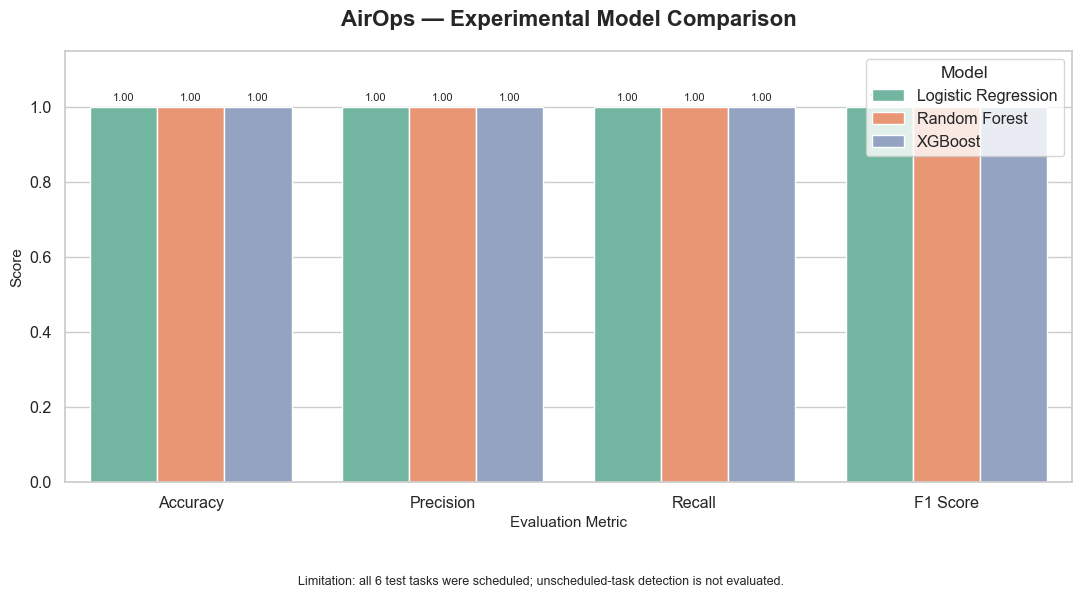

In [72]:
# Select the metrics to visualize
metrics = ["Accuracy", "Precision", "Recall", "F1 Score"]

# Convert the evaluation table into chart-friendly format
plot_data = evaluation_df.melt(
    id_vars="Model",
    value_vars=metrics,
    var_name="Metric",
    value_name="Score"
)

# Create the chart
plt.figure(figsize=(11, 6))

ax = sns.barplot(
    data=plot_data,
    x="Metric",
    y="Score",
    hue="Model",
    palette="Set2"
)

ax.set_title(
    "AirOps — Experimental Model Comparison",
    fontsize=16,
    fontweight="bold",
    pad=18
)
ax.set_xlabel("Evaluation Metric", fontsize=11)
ax.set_ylabel("Score", fontsize=11)
ax.set_ylim(0, 1.15)

# Display the score above each bar
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=3, fontsize=8)

plt.figtext(
    0.5, 0.01,
    "Limitation: all 6 test tasks were scheduled; unscheduled-task detection is not evaluated.",
    ha="center",
    fontsize=9,
    wrap=True
)

plt.legend(title="Model")
plt.tight_layout(rect=[0, 0.07, 1, 1])
plt.show()

In [73]:
unscheduled_tasks = model_data[
    model_data["target_scheduled"] == 0
]

display(
    unscheduled_tasks[
        [
            "task_id",
            "title",
            "duration_minutes",
            "earliest_start",
            "deadline",
            "required_resource_type",
            "required_skill",
            "priority"
        ]
    ]
)

,task_id,title,duration_minutes,earliest_start,deadline,required_resource_type,required_skill,priority
24,TSK-025,Impossible Quick Turnaround,300,2026-07-14 06:00:00.000000,2026-07-14 07:00:00.000000,maintenance_bay,maintenance,5


In [74]:
# Work on a copy; preserve the original dataset
time_check = tasks.copy()

time_check["earliest_start"] = pd.to_datetime(
    time_check["earliest_start"]
)
time_check["deadline"] = pd.to_datetime(
    time_check["deadline"]
)

time_check["available_minutes"] = (
    time_check["deadline"] - time_check["earliest_start"]
).dt.total_seconds() / 60

time_check["window_fits"] = (
    time_check["duration_minutes"]
    <= time_check["available_minutes"]
)

print("Tasks whose duration fits within the time window:")
print(time_check["window_fits"].value_counts())

print("\nTasks whose duration exceeds the time window:")
display(
    time_check.loc[
        ~time_check["window_fits"],
        [
            "task_id",
            "title",
            "duration_minutes",
            "available_minutes",
            "window_fits"
        ]
    ]
)

Tasks whose duration fits within the time window:
window_fits
True     29
False     1
Name: count, dtype: int64

Tasks whose duration exceeds the time window:


,task_id,title,duration_minutes,available_minutes,window_fits
24,TSK-025,Impossible Quick Turnaround,300,60.0,False


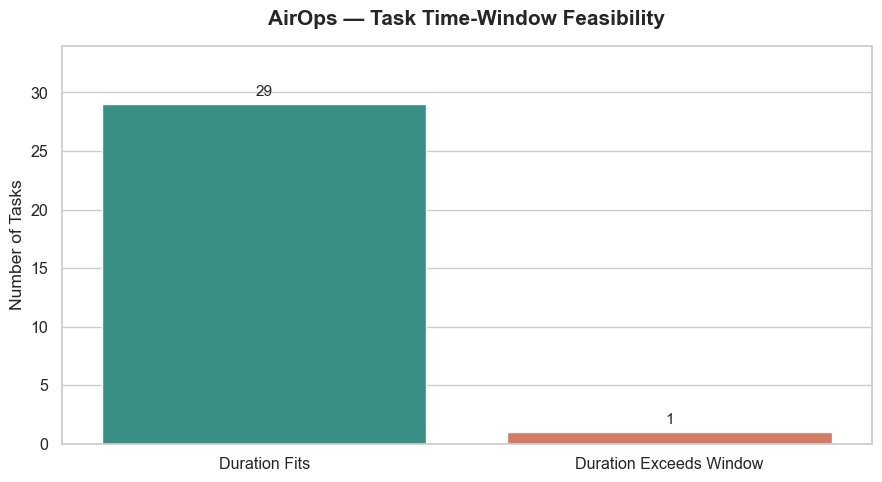

In [75]:
# Summarize the results
feasibility_counts = (
    time_check["window_fits"]
    .map({
        True: "Duration Fits",
        False: "Duration Exceeds Window"
    })
    .value_counts()
    .reindex([
        "Duration Fits",
        "Duration Exceeds Window"
    ], fill_value=0)
    .reset_index()
)

feasibility_counts.columns = ["Result", "Task Count"]

plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=feasibility_counts,
    x="Result",
    y="Task Count",
    hue="Result",
    palette={
        "Duration Fits": "#2A9D8F",
        "Duration Exceeds Window": "#E76F51"
    },
    legend=False
)

ax.set_title(
    "AirOps — Task Time-Window Feasibility",
    fontsize=15,
    fontweight="bold",
    pad=15
)
ax.set_xlabel("")
ax.set_ylabel("Number of Tasks")
ax.set_ylim(0, 34)

for container in ax.containers:
    ax.bar_label(container, fmt="%d", padding=4, fontsize=11)

plt.tight_layout()
plt.show()

## Using RandomForest

In [77]:
best_model_name = "Random Forest"
best_model = models[best_model_name]

print("Selected model:", best_model_name)
print("Reason: A practical baseline for tabular data.")
print("Important: This is a provisional choice, not a proven winner.")
print("All three models had identical test metrics.")

Selected model: Random Forest
Reason: A practical baseline for tabular data.
Important: This is a provisional choice, not a proven winner.
All three models had identical test metrics.


In [78]:
import joblib

joblib.dump(best_model, "airops_random_forest_pipeline.pkl")

print("Model pipeline saved successfully!")

Model pipeline saved successfully!


In [79]:
loaded_model = joblib.load("airops_random_forest_pipeline.pkl")

sample_predictions = loaded_model.predict(X_test)

print("Loaded model:", best_model_name)
print("Predictions:", sample_predictions.tolist())
print("Actual labels:", y_test.tolist())

Loaded model: Random Forest
Predictions: [1, 1, 1, 1, 1, 1]
Actual labels: [1, 1, 1, 1, 1, 1]


## Model Testing

In [81]:
new_task = pd.DataFrame([{
    "category": "maintenance",
    "duration_minutes": 300,
    "priority": 5,
    "required_resource_type": "maintenance_bay",
    "required_skill": "maintenance"
}])

prediction = loaded_model.predict(new_task)[0]
probabilities = loaded_model.predict_proba(new_task)[0]

print("Predicted outcome:",
      "Scheduled" if prediction == 1 else "Unscheduled")

print("Model probability for Scheduled:",
      round(probabilities[list(loaded_model.classes_).index(1)] * 100, 2), "%")

print("\nImportant: This prediction does not verify deadline feasibility.")

Predicted outcome: Scheduled
Model probability for Scheduled: 51.0 %

Important: This prediction does not verify deadline feasibility.


In [82]:
# Example new task
new_task = pd.DataFrame([{
    "category": "maintenance",
    "duration_minutes": 300,
    "priority": 5,
    "required_resource_type": "maintenance_bay",
    "required_skill": "maintenance"
}])

earliest_start = pd.Timestamp("2026-07-14 06:00:00")
deadline = pd.Timestamp("2026-07-14 07:00:00")

# Machine-learning prediction
prediction = loaded_model.predict(new_task)[0]
scheduled_probability = loaded_model.predict_proba(new_task)[0][
    list(loaded_model.classes_).index(1)
]

# Explicit time-window feasibility check
available_minutes = (
    deadline - earliest_start
).total_seconds() / 60

duration = new_task.loc[0, "duration_minutes"]
time_window_fits = duration <= available_minutes

print("ML prediction:",
      "Scheduled" if prediction == 1 else "Unscheduled")

print(f"Estimated scheduled probability: {scheduled_probability:.1%}")
print(f"Required duration: {duration} minutes")
print(f"Available time: {available_minutes:.0f} minutes")
print("Time window feasible:", time_window_fits)

if not time_window_fits:
    print("\nFinal feasibility result: INFEASIBLE")
    print(f"Reason: Task exceeds its available time by "
          f"{duration - available_minutes:.0f} minutes.")
else:
    print("\nFinal feasibility result: Time-window check passed.")
    print("Other resource and scheduling constraints still need checking.")

ML prediction: Scheduled
Estimated scheduled probability: 51.0%
Required duration: 300 minutes
Available time: 60 minutes
Time window feasible: False

Final feasibility result: INFEASIBLE
Reason: Task exceeds its available time by 240 minutes.


## Checks each task’s required duration against its available time window to identify potential deadline conflicts and calculate time shortfalls.

In [84]:
# Use a copy so the original dataset remains unchanged
feasibility_results = tasks.copy()

feasibility_results["earliest_start"] = pd.to_datetime(
    feasibility_results["earliest_start"]
)

feasibility_results["deadline"] = pd.to_datetime(
    feasibility_results["deadline"]
)

feasibility_results["available_minutes"] = (
    feasibility_results["deadline"]
    - feasibility_results["earliest_start"]
).dt.total_seconds() / 60

feasibility_results["time_window_fits"] = (
    feasibility_results["duration_minutes"]
    <= feasibility_results["available_minutes"]
)

feasibility_results["time_shortfall_minutes"] = (
    feasibility_results["duration_minutes"]
    - feasibility_results["available_minutes"]
).clip(lower=0)

# Summarize the results
total_tasks = len(feasibility_results)
feasible_count = feasibility_results["time_window_fits"].sum()
infeasible_count = total_tasks - feasible_count

print("AIR OPS — TIME-WINDOW FEASIBILITY REPORT")
print("-" * 42)
print("Total tasks:", total_tasks)
print("Duration fits:", feasible_count)
print("Duration exceeds window:", infeasible_count)

print("\nTasks requiring attention:")
display(
    feasibility_results.loc[
        ~feasibility_results["time_window_fits"],
        [
            "task_id",
            "title",
            "duration_minutes",
            "available_minutes",
            "time_shortfall_minutes"
        ]
    ]
)

AIR OPS — TIME-WINDOW FEASIBILITY REPORT
------------------------------------------
Total tasks: 30
Duration fits: 29
Duration exceeds window: 1

Tasks requiring attention:


,task_id,title,duration_minutes,available_minutes,time_shortfall_minutes
24,TSK-025,Impossible Quick Turnaround,300,60.0,240.0


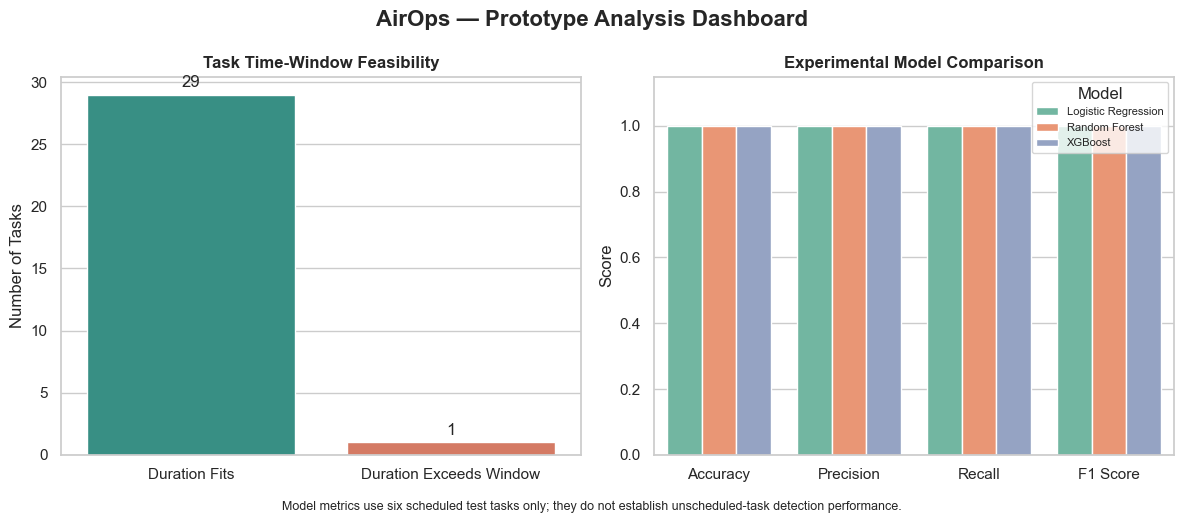

In [85]:
sns.set_theme(style="whitegrid")

# Summary values
total = len(feasibility_results)
fits = int(feasibility_results["time_window_fits"].sum())
exceeds = total - fits

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Chart 1: Task feasibility
feasibility_chart = pd.DataFrame({
    "Result": ["Duration Fits", "Duration Exceeds Window"],
    "Tasks": [fits, exceeds]
})

sns.barplot(
    data=feasibility_chart,
    x="Result",
    y="Tasks",
    hue="Result",
    palette=["#2A9D8F", "#E76F51"],
    legend=False,
    ax=axes[0]
)

axes[0].set_title("Task Time-Window Feasibility", fontweight="bold")
axes[0].set_xlabel("")
axes[0].set_ylabel("Number of Tasks")

for container in axes[0].containers:
    axes[0].bar_label(container, padding=3)

# Chart 2: Model metrics
metrics = ["Accuracy", "Precision", "Recall", "F1 Score"]

plot_data = evaluation_df.melt(
    id_vars="Model",
    value_vars=metrics,
    var_name="Metric",
    value_name="Score"
)

sns.barplot(
    data=plot_data,
    x="Metric",
    y="Score",
    hue="Model",
    palette="Set2",
    ax=axes[1]
)

axes[1].set_title("Experimental Model Comparison", fontweight="bold")
axes[1].set_xlabel("")
axes[1].set_ylabel("Score")
axes[1].set_ylim(0, 1.15)
axes[1].legend(title="Model", fontsize=8)

fig.suptitle("AirOps — Prototype Analysis Dashboard",
             fontsize=16, fontweight="bold")

fig.text(
    0.5, -0.02,
    "Model metrics use six scheduled test tasks only; they do not establish "
    "unscheduled-task detection performance.",
    ha="center",
    fontsize=9
)

plt.tight_layout()
plt.show()

In [86]:
# Save the full feasibility results
feasibility_results.to_csv(
    "airops_feasibility_report.csv",
    index=False
)

# Save the experimental model comparison
evaluation_df.to_csv(
    "airops_model_comparison.csv",
    index=False
)

print("Saved successfully:")
print("1. airops_feasibility_report.csv")
print("2. airops_model_comparison.csv")
print("3. airops_random_forest_pipeline.pkl (saved earlier)")